# 07 · Voz: reconocimiento, síntesis y clonación

Este es un módulo de Neural Networks 1002. Supone, de forma general, el [módulo 06 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/06-generacion-de-audio-y-video/) (representaciones de audio: formas de onda, espectrogramas, bancos de filtros mel; repasamos lo necesario), y el [módulo 06 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/06-redes-recurrentes/) (redes recurrentes), el [módulo 08](https://neural-networks.academy.forwardforecasting.eu/es/08-embeddings-y-traduccion/) (procesamiento clásico del lenguaje natural) y el [módulo 09](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) (el transformer).

La voz es la interfaz más natural entre personas y máquinas, y tres familias de modelos la hacen posible: el **reconocimiento automático del habla** (ASR, del inglés automatic speech recognition: entra audio, sale texto), la **síntesis de voz a partir de texto** (TTS, text to speech: entra texto, sale audio) y los **modelos de locutor** (entra audio, sale "quién habla"). Combinados dan la traducción de voz y la clonación de voz, y la misma tecnología que permite hablar de nuevo a quien perdió la voz permite a un estafador llamar por teléfono a tu abuela. Este módulo construye las ideas, ejecuta los sistemas reales en una CPU y los mide, incluido cómo fallan.

En este cuaderno, en CPU y con semillas fijas:

1. miraremos la **cadena del habla**: forma de onda, rasgos log-mel, modelo acústico, texto (y el camino inverso);
2. construiremos un **reconocedor CTC desde cero** (CTC, del inglés connectionist temporal classification, clasificación temporal conexionista): la pérdida calculada a mano, una pequeña red recurrente entrenada con dígitos hablados, decodificación **voraz** y por **búsqueda en haz**, y la **tasa de error de palabras** (WER, word error rate) con locutores que nunca ha oído;
3. ejecutaremos **reconocedores reales preentrenados**, Whisper (tiny y base) y wav2vec 2.0, y mediremos la WER con habla leída real, con ruido añadido, con distintos acentos y con silencio, donde Whisper **alucina**;
4. ejecutaremos un **TTS real preentrenado** (SpeechT5 con un vocoder HiFi-GAN), lo abriremos etapa por etapa y lo juzgaremos sin escuchar mediante la **WER de ida y vuelta** (TTS y luego ASR);
5. encadenaremos modelos en una **cascada de traducción de voz a voz** (ASR, traducción automática Marian, TTS), con identificación de idioma y traducción al inglés con Whisper, y mediremos cada etapa;
6. mediremos la **similitud entre locutores** con embeddings ECAPA-TDNN, **condicionaremos un TTS a un embedding de locutor**, probaremos cuán bien se puede clonar una voz a partir de una referencia corta (usando solo voces sintéticas) y veremos por qué la clonación de disparo cero con modelos de lenguaje de códec es a la vez potente y arriesgada;
7. nos enfrentaremos a la **ética**: consentimiento, fraude con voces falsas, un **detector** de juguete medido que falla con un generador no visto, una **marca de agua** de juguete y el marco legal.

**Contenido**

1. La cadena del habla
2. Un reconocedor CTC desde cero
3. Reconocimiento real: Whisper y wav2vec 2.0
4. Síntesis de voz: SpeechT5 y HiFi-GAN
5. Traducción de voz a voz como cascada
6. Embeddings de locutor, similitud y clonación de voz
7. Ética, consentimiento, fraude, detección, marcas de agua y ley
8. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [06 Representaciones de audio (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/06-generacion-de-audio-y-video/) | frecuencia de muestreo, espectrograma, escala mel (repasados en la sección 1) |
| [06 Redes recurrentes (1001)](https://neural-networks.academy.forwardforecasting.eu/es/06-redes-recurrentes/) | capas GRU (gated recurrent unit, unidad recurrente con puertas) sobre secuencias |
| [08 PLN clásico (1001)](https://neural-networks.academy.forwardforecasting.eu/es/08-embeddings-y-traduccion/) | tokens, distancia de edición, por qué el texto necesita un vocabulario |
| [09 El transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | atención codificador-decodificador, con la que están construidos Whisper y SpeechT5 |

¿Nuevo en PyTorch? El [curso Python 1001, sección de marcos de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo presenta.

**Preparación.** Además de los requisitos del curso, este cuaderno usa `pip install transformers soundfile sentencepiece sacremoses speechbrain scipy pandas pyarrow`. Los modelos preentrenados y los pequeños conjuntos de datos se descargan una vez en `~/.cache/nn1002` y en la caché de Hugging Face (unos 3 GB en total, sin cuenta ni clave de API). Licencias, indicadas donde se usa cada recurso por primera vez: Free Spoken Digit Dataset CC BY-SA 4.0; LibriSpeech CC BY 4.0; SpeechT5 MIT; Whisper, wav2vec 2.0, SpeechBrain y la mayoría de los modelos Opus-MT Apache 2.0 (según sus fichas de modelo; el repositorio de código de Whisper es MIT); los modelos de síntesis MMS CC BY-NC 4.0 (no comercial, válido para enseñar).

**En qué se diferencian los juguetes de los sistemas reales.** Nuestro reconocedor desde cero oye diez palabras aisladas de seis locutores (unos 3000 clips cortos); Whisper se entrenó con 680 000 horas de audio y wav2vec 2.0 con 960 horas etiquetadas más 53 000 horas de habla sin etiquetar. Nuestras mediciones con un puñado de frases son muestras pequeñas: ilustran los comportamientos, no clasifican los sistemas. **Tiempo y Google Colab.** El cuaderno está dimensionado para un entorno de CPU gratuito de Colab (unas 2 CPU virtuales, 12 GB de memoria, sin GPU). Medido con 2 hilos en una CPU rápida de la nube y con los modelos ya en caché, todo el cuaderno se ejecuta en unos 5,5 minutos. Espera entre 10 y 15 minutos en Colab, cuyos núcleos son más lentos, más una descarga única de unos 3 GB de modelos; con una máquina de 8 núcleos es más rápido. El código dimensiona sus hilos a partir de `os.cpu_count()` (se puede cambiar con la variable de entorno `NN_THREADS`).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/07_voz_reconocimiento_sintesis_y_clonacion.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 12 minutos, con un pico de memoria de unos 6,3 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'soundfile': 'soundfile',
    'speechbrain': 'speechbrain',
    'torch': 'torch',
    'torchaudio': 'torchaudio',
    'transformers': 'transformers',
    'sentencepiece': 'sentencepiece',
    'sacremoses': 'sacremoses',
    'pyarrow': 'pyarrow',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import os, io, re, time, math, zipfile, urllib.request, itertools, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.signal import resample_poly
import transformers
transformers.logging.set_verbosity_error()
from IPython.display import Audio, display

NCPU = int(os.environ.get("NN_THREADS", min(8, os.cpu_count() or 2)))      # Colab tiene unas 2 CPU virtuales
torch.set_num_threads(NCPU)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
T_START = time.time()
CACHE = os.path.expanduser("~/.cache/nn1002"); os.makedirs(CACHE, exist_ok=True)

# ---------- funciones auxiliares compartidas por todas las secciones ----------
def edit_distance(ref, hyp):
    # distancia de Levenshtein entre dos secuencias (listas de palabras o de caracteres)
    d = list(range(len(hyp) + 1))
    for i in range(1, len(ref) + 1):
        prev, d[0] = d[:], i
        for j in range(1, len(hyp) + 1):
            d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (ref[i - 1] != hyp[j - 1]))
    return d[-1]

def wer(refs, hyps):
    # tasa de error de palabras: (sustituciones + eliminaciones + inserciones) / palabras de las referencias
    e = sum(edit_distance(r.split(), h.split()) for r, h in zip(refs, hyps))
    return e / max(1, sum(len(r.split()) for r in refs))

def cer(refs, hyps):
    e = sum(edit_distance(list(r), list(h)) for r, h in zip(refs, hyps))
    return e / max(1, sum(len(r) for r in refs))

def norm(t):
    # minúsculas y sin puntuación: la normalización habitual antes de calcular la WER
    t = t.lower().replace("-", " ")
    return " ".join(re.sub(r"[^a-z0-9' ]", " ", t).split())

def play(a, sr=16000, label=""):
    if label: print(label)
    display(Audio(np.clip(a, -1, 1), rate=sr))

def to16k(a, sr):
    return resample_poly(a, 16000 // math.gcd(16000, sr), sr // math.gcd(16000, sr)).astype(np.float32)

print("torch", torch.__version__, "| transformers", transformers.__version__, "| threads", torch.get_num_threads())

torch 2.15.0+cpu | transformers 5.24.1 | threads 8


## 1. La cadena del habla

El sonido es presión del aire a lo largo del tiempo. Un micrófono lo muestrea, normalmente 16 000 veces por segundo (la **frecuencia de muestreo**, 16 kHz), y da un vector largo de números, la **forma de onda**. Las formas de onda en bruto son una mala entrada para una red: el habla tiene estructura a varias escalas (una vocal de 25 ms, una palabra de 300 ms, una frase de 3 s) y la misma palabra se ve completamente distinta en la forma de onda según quién la diga. Por eso casi todos los sistemas de voz calculan primero un **espectrograma log-mel**:

1. se corta la forma de onda en ventanas solapadas (de 25 ms cada 10 ms, el llamado **salto**, hop);
2. se toma el módulo de la transformada de Fourier en cada ventana (cuánta energía hay en cada frecuencia);
3. se agrupan las frecuencias con un banco de filtros triangulares espaciados en la **escala mel** (resolución fina en bajas frecuencias y gruesa en altas, más o menos como el oído), por ejemplo 40 u 80 filtros;
4. se toma el logaritmo (la sonoridad se percibe más o menos de forma logarítmica, y una ganancia multiplicativa pasa a ser un desplazamiento aditivo).

El resultado es una imagen con el tiempo en un eje y de 40 a 128 "bandas de frecuencia" en el otro; los modelos de voz la tratan como una imagen corta y ancha. Las dos grandes tareas son entonces

$$\text{ASR:}\quad \text{audio} \;\to\; \text{log-mel} \;\to\; \text{modelo acústico} \;\to\; \text{texto} \qquad\qquad \text{TTS:}\quad \text{texto} \;\to\; \text{modelo acústico} \;\to\; \text{log-mel} \;\to\; \text{vocoder} \;\to\; \text{audio}$$

donde el **vocoder** es una red neuronal que convierte un espectrograma mel otra vez en forma de onda (el espectrograma descartó la fase, que el vocoder tiene que inventar). Los **modelos de locutor** comprimen un clip en un vector corto (un **embedding**) que dice quién habla, no qué se dice. Empezamos con los datos que usaremos en la parte desde cero.

**Datos: el Free Spoken Digit Dataset** (FSDD; Jackson et al., [doi:10.5281/zenodo.1342401](https://doi.org/10.5281/zenodo.1342401), [GitHub](https://github.com/Jakobovski/free-spoken-digit-dataset), licencia [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)): 3000 grabaciones a 8 kHz de los dígitos 0 a 9, 50 por dígito de cada uno de 6 locutores que las publicaron abiertamente, con los acentos registrados en los metadatos del propio conjunto. Es pequeño (16 MB), así que lo descargamos una vez y lo guardamos en caché. El banco de filtros mel de abajo está escrito desde cero, en unas diez líneas.

3000 grabaciones; locutores: ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler'] | duración media 0.44 s


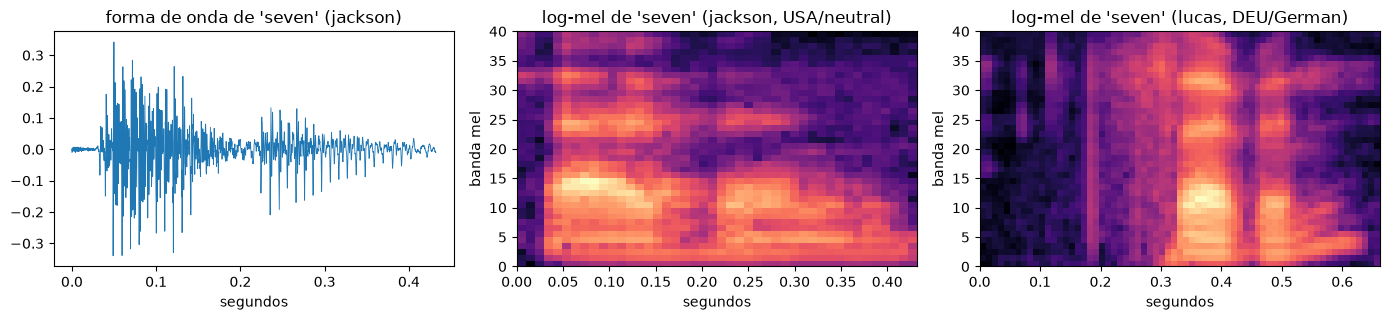

'seven' dicho por jackson (8 kHz):


In [2]:
FSDD_ZIP = CACHE + "/fsdd.zip"
if not os.path.exists(FSDD_ZIP):
    urllib.request.urlretrieve("https://github.com/Jakobovski/free-spoken-digit-dataset/archive/refs/tags/v1.0.10.zip", FSDD_ZIP)
zf = zipfile.ZipFile(FSDD_ZIP)
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
ACCENT = {"jackson": "USA/neutral", "theo": "USA/neutral", "nicolas": "BEL/French", "george": "GRC/Greek", "yweweler": "DEU/German", "lucas": "DEU/German"}
fsdd = []
for n in zf.namelist():
    m = re.search(r"recordings/(\d)_(\w+)_(\d+)\.wav$", n)
    if m:
        a, sr = sf.read(io.BytesIO(zf.read(n)), dtype="float32"); assert sr == 8000
        fsdd.append(dict(digit=int(m.group(1)), spk=m.group(2), idx=int(m.group(3)), audio=a))
print(len(fsdd), "grabaciones; locutores:", sorted({c["spk"] for c in fsdd}), "| duración media %.2f s" % np.mean([len(c["audio"]) / 8000 for c in fsdd]))

# ---- espectrograma log-mel desde cero ----
def mel_filterbank(sr, n_fft, n_mels, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))     # n_mels + 2 puntos en el eje mel
    freqs = np.fft.rfftfreq(n_fft, 1 / sr)
    fb = np.zeros((n_mels, len(freqs)))
    for i in range(n_mels):                                                  # un triángulo por banda
        lo, mid, hi = edges[i:i + 3]
        fb[i] = np.maximum(0, np.minimum((freqs - lo) / (mid - lo), (hi - freqs) / (hi - mid)))
    return torch.tensor(fb, dtype=torch.float32)

_FB = {}
def logmel(a, sr=8000, n_fft=256, hop=80, n_mels=40):
    key = (sr, n_fft, n_mels)
    if key not in _FB: _FB[key] = mel_filterbank(sr, n_fft, n_mels)
    S = torch.stft(torch.tensor(a), n_fft, hop, window=torch.hann_window(n_fft), return_complex=True).abs() ** 2
    return torch.log(_FB[key] @ S + 1e-6).T          # (fotogramas, bandas mel)

by_spk = {}
for c in fsdd: by_spk.setdefault(c["spk"], []).append(c)
seven = {s: next(c["audio"] for c in fsdd if c["digit"] == 7 and c["spk"] == s and c["idx"] == 0) for s in ["jackson", "lucas"]}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].plot(np.arange(len(seven["jackson"])) / 8000, seven["jackson"], lw=0.6); ax[0].set_title("forma de onda de 'seven' (jackson)"); ax[0].set_xlabel("segundos")
for k, s in enumerate(["jackson", "lucas"]):
    M = logmel(seven[s]).numpy().T
    ax[k + 1].imshow(M, origin="lower", aspect="auto", cmap="magma", extent=[0, len(seven[s]) / 8000, 0, 40])
    ax[k + 1].set_title("log-mel de 'seven' (%s, %s)" % (s, ACCENT[s])); ax[k + 1].set_xlabel("segundos"); ax[k + 1].set_ylabel("banda mel")
plt.tight_layout(); plt.show()
play(seven["jackson"], 8000, "'seven' dicho por jackson (8 kHz):")

**Lectura.** La misma palabra dicha por dos locutores da patrones parecidos pero no idénticos: las dos ráfagas de energía de la fricativa "s" al principio y de la "v" y la "n" al final, y las bandas que suben y bajan durante las vocales, se desplazan en el tiempo y en la frecuencia según la voz, la velocidad y el acento. Un modelo acústico tiene que aprender cuál de esas variaciones importa (la palabra) y cuál no (el locutor). Un segundo problema es la **alineación**: una grabación de tres dígitos tiene unos 200 fotogramas pero una transcripción de tres palabras, y nadie nos dice qué fotograma pertenece a qué letra. La sección 2 muestra el truco que resolvió esto durante una década de reconocimiento del habla.

## 2. Un reconocedor CTC desde cero

### 2.1 El problema de la alineación y la pérdida CTC

Queremos una red que lea $T$ fotogramas de rasgos log-mel y escriba una transcripción de $L$ caracteres, con $L$ normalmente mucho menor que $T$ y sin etiquetas a nivel de fotograma. La **clasificación temporal conexionista** (CTC; Graves et al., 2006, [artículo](https://www.cs.toronto.edu/~graves/icml_2006.pdf)) lo consigue con dos ideas.

1. La red produce, en **cada** fotograma $t$, una distribución de probabilidad sobre los caracteres más un símbolo especial, el **blanco** ($\varnothing$, "nada nuevo aquí"). Llamamos $y_t(k)$ a la probabilidad del símbolo $k$ en el fotograma $t$.
2. Una secuencia fotograma a fotograma $\pi = (\pi_1, \dots, \pi_T)$ (un **camino**) se convierte en texto con la aplicación de colapso $\mathcal{B}$: primero se fusionan los símbolos repetidos y luego se eliminan los blancos. Así `hh∅e∅ll∅ll∅o` se convierte en `hello`, y el blanco entre las dos `ll` es lo que permite que sobreviva una letra doble real.

La probabilidad de una transcripción $\ell$ es la suma sobre **todos los caminos que colapsan a ella**, suponiendo que los fotogramas son independientes dado el audio:

$$P(\ell \mid x) = \sum_{\pi:\,\mathcal{B}(\pi) = \ell}\; \prod_{t=1}^{T} y_t(\pi_t), \qquad \mathcal{L}_\text{CTC} = -\ln P(\ell \mid x).$$

Hay una cantidad exponencial de caminos, pero un **programa dinámico** (el algoritmo hacia adelante) los suma en tiempo $O(T \cdot L)$: se escribe el objetivo con blancos alrededor de cada símbolo, $\ell' = \varnothing\, \ell_1 \varnothing\, \ell_2 \dots \ell_L \varnothing$, y sea $\alpha_t(s)$ la probabilidad de todos los prefijos de camino de longitud $t$ que terminan en la posición $s$ de $\ell'$. Entonces $\alpha_t(s) = \big(\alpha_{t-1}(s) + \alpha_{t-1}(s-1) + [\,\ell'_s \ne \varnothing,\ \ell'_s \ne \ell'_{s-2}\,]\;\alpha_{t-1}(s-2)\big)\, y_t(\ell'_s)$ y $P(\ell \mid x) = \alpha_T(|\ell'|) + \alpha_T(|\ell'| - 1)$. Como es una suma diferenciable, los gradientes llegan a la red y la alineación queda **marginalizada**, nunca elegida. Comprobémoslo en un caso lo bastante pequeño para enumerarlo: 4 fotogramas, símbolos $\{\varnothing, a, b\}$, objetivo "ab".

In [3]:
torch.manual_seed(0)
T_toy, V_toy = 4, 3                                  # 4 fotogramas, símbolos: 0 = blanco, 1 = 'a', 2 = 'b'
lp = torch.randn(T_toy, V_toy).log_softmax(-1)       # log-probabilidades por fotograma de una red de mentira

def collapse(path):                                  # la aplicación B: fusionar repetidos y luego quitar blancos
    out, prev = [], None
    for s in path:
        if s != prev and s != 0: out.append(s)
        prev = s
    return tuple(out)

def collapse_str(s):
    return "".join(ch for i, ch in enumerate(s) if ch != "_" and (i == 0 or ch != s[i - 1]))
print("collapse('hh_e_ll_ll_o') ->", collapse_str("hh_e_ll_ll_o"), "| collapse('hhheeellloo') ->", collapse_str("hhheeellloo"))

# 1) fuerza bruta: enumerar los 3^4 = 81 caminos y sumar los que colapsan a "ab" = (1, 2)
good = [p for p in itertools.product(range(V_toy), repeat=T_toy) if collapse(p) == (1, 2)]
p_brute = sum(math.exp(sum(lp[t, s].item() for t, s in enumerate(p))) for p in good)
print("caminos que colapsan a 'ab':", len(good), "of", V_toy ** T_toy, "->", good)

# 2) el programa dinámico hacia adelante sobre el objetivo extendido con blancos  [_, a, _, b, _]
def ctc_forward(lp, target):
    ext = [0]
    for s in target: ext += [s, 0]
    T, S = lp.shape[0], len(ext)
    alpha = np.zeros((T, S)); alpha[0, 0] = lp[0, 0].exp().item(); alpha[0, 1] = lp[0, ext[1]].exp().item()
    for t in range(1, T):
        for s in range(S):
            a = alpha[t - 1, s] + (alpha[t - 1, s - 1] if s >= 1 else 0)
            if s >= 2 and ext[s] != 0 and ext[s] != ext[s - 2]: a += alpha[t - 1, s - 2]
            alpha[t, s] = a * lp[t, ext[s]].exp().item()
    return alpha[-1, -1] + alpha[-1, -2], alpha
p_dp, alpha = ctc_forward(lp, [1, 2])

# 3) la implementación de PyTorch
loss_torch = F.ctc_loss(lp[:, None, :], torch.tensor([[1, 2]]), torch.tensor([T_toy]), torch.tensor([2]), blank=0, reduction="sum")
print("-ln P  fuerza bruta: %.6f | algoritmo hacia adelante: %.6f | F.ctc_loss: %.6f" % (-math.log(p_brute), -math.log(p_dp), loss_torch.item()))

collapse('hh_e_ll_ll_o') -> hello | collapse('hhheeellloo') -> helo
caminos que colapsan a 'ab': 15 of 81 -> [(0, 0, 1, 2), (0, 1, 0, 2), (0, 1, 1, 2), (0, 1, 2, 0), (0, 1, 2, 2), (1, 0, 0, 2), (1, 0, 2, 0), (1, 0, 2, 2), (1, 1, 0, 2), (1, 1, 1, 2), (1, 1, 2, 0), (1, 1, 2, 2), (1, 2, 0, 0), (1, 2, 2, 0), (1, 2, 2, 2)]
-ln P  fuerza bruta: 1.299563 | algoritmo hacia adelante: 1.299563 | F.ctc_loss: 1.299563


**Lectura.** Los tres números coinciden hasta seis cifras: enumerar los caminos, la recursión $O(T \cdot L)$ y la `ctc_loss` de PyTorch calculan lo mismo. De los 81 caminos posibles de 4 fotogramas solo 15 colapsan a "ab" (por ejemplo `a b ∅ ∅`, `∅ a a b`, `a ∅ b b`), y la pérdida es menos el logaritmo de su probabilidad total. El entrenamiento empuja masa de probabilidad hacia *algunos* de esos caminos sin elegir nunca cuál; en la práctica las redes convergen a salidas **picudas**: un fotograma emite el carácter y los demás emiten blanco, como veremos en el gráfico de posteriores. CTC supone que los fotogramas son condicionalmente independientes, así que no tiene modelo de lenguaje incorporado; eso importa en la sección 2.4.

### 2.2 Datos: secuencias de dígitos hablados, con locutores reservados

Los dígitos aislados no necesitarían CTC, así que construimos **secuencias** de 3 a 5 dígitos pegando grabaciones con pequeños huecos de silencio (pegamos los rasgos en lugar de las formas de onda, lo que es más rápido y casi equivalente). La transcripción son las palabras deletreadas, `"seven two nine"`, de modo que los símbolos de salida son las 15 letras que aparecen en los nombres de los dígitos en inglés, el espacio y el blanco (17 en total): un modelo **a nivel de carácter**, como los reconocedores reales. Particiones:

* **entrenamiento**: 5 locutores, grabaciones numeradas de 5 a 49 (la convención del propio conjunto pone de 0 a 4 en la prueba);
* **locutores vistos, grabaciones nuevas**: los mismos 5 locutores, grabaciones de 0 a 4;
* **locutor no visto**: *lucas* (acento alemán), nunca usado en el entrenamiento, todas sus grabaciones.

In [4]:
feats = [dict(c, f=logmel(c["audio"])) for c in fsdd]                       # (fotogramas, 40) por clip
allf = torch.cat([c["f"] for c in feats]); MU, SD = allf.mean(0), allf.std(0)
NM = 40
SIL = torch.full((1, NM), math.log(1e-6))                                    # un fotograma "silencioso"
VOCAB = ["_"] + sorted(set("".join(WORDS))) + [" "]                          # "_" es el blanco de CTC
c2i = {c: i for i, c in enumerate(VOCAB)}
TRAIN_SPK, HELD = ["jackson", "theo", "nicolas", "george", "yweweler"], "lucas"
pool = {}
for c in feats: pool.setdefault((c["spk"], c["idx"] < 5), []).append((c["digit"], c["f"]))

def make_sequence(rng, spks, test, noise=0.0):
    k = rng.integers(3, 6); digits, parts = [], []
    for _ in range(k):
        cand = pool[(spks[rng.integers(len(spks))], test)]
        d, f = cand[rng.integers(len(cand))]
        parts += [SIL.expand(rng.integers(3, 20), NM), f]; digits.append(d)
    parts.append(SIL.expand(rng.integers(3, 20), NM))
    X = (torch.cat(parts) - MU) / SD
    return (X + noise * torch.randn_like(X) if noise else X), digits

def spell(digits): return " ".join(WORDS[d] for d in digits)

def batchify(items):
    T = max(len(x) for x, _ in items)
    X = torch.zeros(len(items), T, NM); lens = torch.tensor([len(x) for x, _ in items])
    for i, (x, _) in enumerate(items): X[i, :len(x)] = x
    tg = [torch.tensor([c2i[c] for c in spell(d)]) for _, d in items]
    return X, lens, torch.cat(tg), torch.tensor([len(t) for t in tg])

rng0 = np.random.default_rng(0)
x, d = make_sequence(rng0, TRAIN_SPK, False)
print("un ejemplo de entrenamiento: dígitos", d, "->", repr(spell(d)), "| fotogramas:", len(x), "| caracteres objetivo:", len(spell(d)))
print("vocabulario (%d símbolos):" % len(VOCAB), "".join(VOCAB))

un ejemplo de entrenamiento: dígitos [5, 0, 1, 9, 9] -> 'five zero one nine nine' | fotogramas: 331 | caracteres objetivo: 23
vocabulario (17 símbolos): _efghinorstuvwxz 


### 2.3 El modelo y su entrenamiento

Dos convoluciones 1-D con paso (cada una divide por dos el número de fotogramas, de modo que la red trabaja a 25 fotogramas por segundo, de sobra para 29 caracteres de salida en unos 4 s) alimentan una GRU **bidireccional** de 2 capas (lee la secuencia hacia adelante y hacia atrás, de modo que cada fotograma ve su contexto a ambos lados), y una capa lineal produce las 17 log-probabilidades por fotograma. Entrenamos con la pérdida CTC, AdamW y un calendario de tasa de aprendizaje de un ciclo, añadiendo ruido gaussiano a los rasgos como aumento de datos barato.

parámetros: 606737


paso    0  pérdida CTC 5.398


paso  100  pérdida CTC 1.602


paso  200  pérdida CTC 0.087


paso  300  pérdida CTC 0.013


paso  400  pérdida CTC 0.008


el entrenamiento tardó 61 s


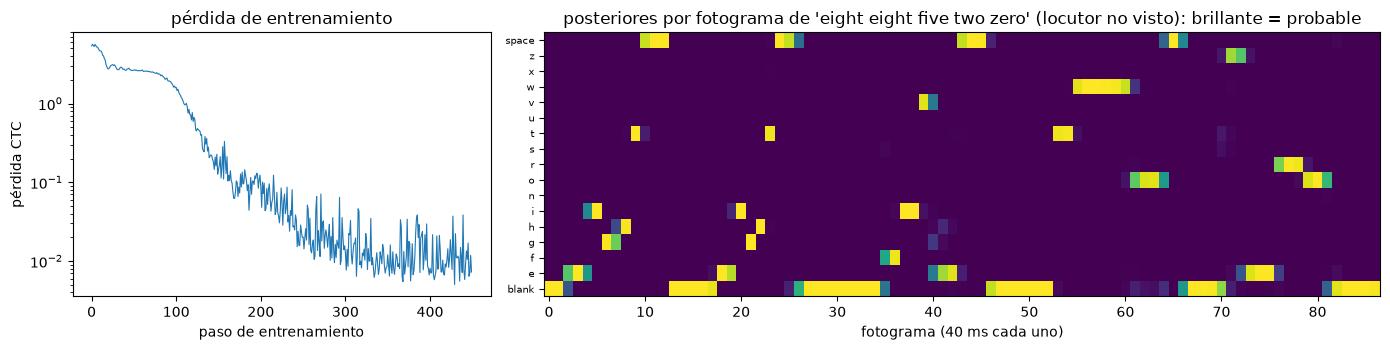

In [5]:
class CTCNet(nn.Module):
    def __init__(s, h=128):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(NM, h, 5, 2, 2), nn.GELU(), nn.Conv1d(h, h, 5, 2, 2), nn.GELU())   # 4 veces menos fotogramas
        s.rnn = nn.GRU(h, h, 2, batch_first=True, bidirectional=True, dropout=0.1)
        s.out = nn.Linear(2 * h, len(VOCAB))
    def forward(s, X, lens):
        z = s.conv(X.transpose(1, 2)).transpose(1, 2)
        return s.out(s.rnn(z)[0]).log_softmax(-1), (lens + 3) // 4          # log-probabilidades (lote, T/4, 17) y sus longitudes

torch.manual_seed(0); rng = np.random.default_rng(0)
net = CTCNet(); print("parámetros:", sum(p.numel() for p in net.parameters()))
STEPS = 450
opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=STEPS)
t0 = time.time(); losses = []
for step in range(STEPS):
    X, L, tg, tl = batchify([make_sequence(rng, TRAIN_SPK, False, noise=0.1) for _ in range(32)])
    lp_b, ol = net(X, L)
    loss = F.ctc_loss(lp_b.transpose(0, 1), tg, ol, tl, blank=0, zero_infinity=True)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 5.0); opt.step(); sched.step()
    losses.append(loss.item())
    if step % 100 == 0: print("paso %4d  pérdida CTC %.3f" % (step, loss.item()))
print("el entrenamiento tardó %.0f s" % (time.time() - t0))
net.eval()

# posteriores de una emisión del locutor no visto
r = np.random.default_rng(5); xs, ds = make_sequence(r, [HELD], False)
with torch.no_grad(): lp_u, ol_u = net(xs[None], torch.tensor([len(xs)]))
P = lp_u[0].exp().numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2]})
ax[0].semilogy(losses, lw=0.8); ax[0].set_xlabel("paso de entrenamiento"); ax[0].set_ylabel("pérdida CTC"); ax[0].set_title("pérdida de entrenamiento")
ax[1].imshow(P.T, origin="lower", aspect="auto", cmap="viridis")
ax[1].set_yticks(range(len(VOCAB))); ax[1].set_yticklabels(["blank" if c == "_" else ("space" if c == " " else c) for c in VOCAB], fontsize=7)
ax[1].set_xlabel("fotograma (40 ms cada uno)"); ax[1].set_title("posteriores por fotograma de '%s' (locutor no visto): brillante = probable" % spell(ds))
plt.tight_layout(); plt.show()

**Lectura.** La pérdida baja de alrededor de 5 a casi cero en unos cientos de pasos. El gráfico de posteriores muestra el comportamiento característico de CTC: la fila del blanco es brillante casi en todas partes, y cada carácter aparece como una raya vertical corta y nítida en el fotograma en que la red decidió que estaba completo, normalmente *después* de que haya pasado parte del sonido. La red nunca vio una alineación y aun así aprendió una coherente. A continuación, cómo leer la transcripción a partir de esos posteriores.

### 2.4 Decodificación: voraz, búsqueda en haz y un léxico de palabras

* **Decodificación voraz**: tomar el símbolo más probable en cada fotograma y aplicar después la aplicación de colapso $\mathcal{B}$. Es rápida, pero se compromete pronto e ignora que muchos caminos colapsan al mismo texto.
* **Búsqueda en haz de prefijos** (Hannun, 2014, [arXiv 1408.2873](https://arxiv.org/abs/1408.2873)): se mantienen los $B$ mejores *prefijos de texto* (no caminos) y, para cada uno, la probabilidad total de todos los caminos que colapsan a él, dividida en "termina en blanco" y "termina en un carácter" para tratar bien las letras repetidas. Esto suma sobre alineaciones, que es exactamente lo que hace la pérdida.
* **Fusión superficial con un léxico**: CTC no tiene conocimiento del idioma, pero sabemos que cada palabra es el nombre de un dígito. En cada frontera de palabra sumamos una bonificación $\beta$ a la puntuación de un prefijo cuya última palabra es un nombre de dígito válido y la restamos en caso contrario. Los sistemas reales hacen lo mismo con un modelo de lenguaje de $n$-gramas o neuronal.

In [6]:
def greedy_decode(lp_t):
    ids, out, prev = lp_t.argmax(-1).tolist(), [], None
    for i in ids:
        if i != prev and i != 0: out.append(VOCAB[i])
        prev = i
    return "".join(out)

NEG = -1e30
def lse(a, b):
    if a < b: a, b = b, a
    return a if b <= NEG else a + math.log1p(math.exp(b - a))

def beam_decode(lp_np, beam=8, lexicon=None, beta=0.0, prune=-7.0):
    # búsqueda en haz de prefijos. haces: prefijo -> [log P(termina en blanco), log P(termina en un carácter)]
    def bonus(prefix):                                       # puntuar la última palabra (terminada) de un prefijo
        if lexicon is None: return 0.0
        w = prefix.rstrip().split(" ")[-1]
        return beta if w in lexicon else -beta
    beams = {"": [0.0, NEG]}
    for t in range(lp_np.shape[0]):
        nxt = {}
        def add(prefix, which, v):
            e = nxt.setdefault(prefix, [NEG, NEG]); e[which] = lse(e[which], v)
        for prefix, (pb, pnb) in beams.items():
            tot = lse(pb, pnb)
            for k in np.where(lp_np[t] > prune)[0]:
                p = lp_np[t, k]
                if k == 0: add(prefix, 0, tot + p); continue
                c = VOCAB[k]
                if prefix and prefix[-1] == c:
                    add(prefix, 1, pnb + p)                  # repetición sin blanco intermedio: mismo prefijo
                    new = prefix + c; add(new, 1, pb + p)    # repetición tras un blanco: una letra doble de verdad
                else:
                    if c == " " and (prefix == "" or prefix[-1] == " "): continue
                    new = prefix + c
                    add(new, 1, tot + p + (bonus(prefix) if c == " " else 0.0))
        beams = dict(sorted(nxt.items(), key=lambda kv: -lse(*kv[1]))[:beam])
    best = max(beams.items(), key=lambda kv: lse(*kv[1]) + bonus(kv[0]))
    return best[0].strip()

LEX = set(WORDS)

def evaluate(spks, test, n=120, seed=1, noise=0.0):
    r = np.random.default_rng(seed); items = [make_sequence(r, spks, test, noise) for _ in range(n)]
    X, L, _, _ = batchify(items)
    with torch.no_grad(): lpb, ol = net(X, L)
    refs = [spell(d) for _, d in items]
    out = {"greedy": [], "beam 8": [], "beam 8 + lexicon": []}
    for k in range(n):
        l = lpb[k, :ol[k]]
        out["greedy"].append(greedy_decode(l))
        out["beam 8"].append(beam_decode(l.numpy(), 8))
        out["beam 8 + lexicon"].append(beam_decode(l.numpy(), 8, LEX, 2.0))
    return refs, out

sets = {"locutores vistos, grabaciones nuevas": dict(spks=TRAIN_SPK, test=True),
        "locutores vistos, rasgos con ruido": dict(spks=TRAIN_SPK, test=True, noise=0.7),
        "locutor no visto (lucas, acento alemán)": dict(spks=[HELD], test=False)}
rows, store = [], {}
t0 = time.time()
for name, kw in sets.items():
    refs, out = evaluate(**kw); store[name] = (refs, out)
    for dec, hyp in out.items():
        rows.append(dict(test_set=name, decoder=dec, WER=round(wer(refs, hyp), 3), CER=round(cer(refs, hyp), 3)))
res = pd.DataFrame(rows); display(res.pivot(index="test_set", columns="decoder", values="WER")[["greedy", "beam 8", "beam 8 + lexicon"]])
print("la decodificación tardó %.0f s" % (time.time() - t0))
refs, out = store["locutor no visto (lucas, acento alemán)"]
bad = [i for i in range(len(refs)) if out["greedy"][i] != refs[i]][:4]
for i in bad:
    print("ref    :", refs[i]); print("greedy :", out["greedy"][i]); print("beam   :", out["beam 8"][i]); print("+lexicon:", out["beam 8 + lexicon"][i]); print()

decoder,greedy,beam 8,beam 8 + lexicon
test_set,,,
"locutor no visto (lucas, acento alemán)",0.299,0.287,0.193
"locutores vistos, grabaciones nuevas",0.011,0.011,0.008
"locutores vistos, rasgos con ruido",0.032,0.030,0.019


la decodificación tardó 2 s
ref    : five nine one nine
greedy : five nie one nine
beam   : five nine one nine
+lexicon: five nine one nine

ref    : four eight four five zero
greedy : four eight one five zeroe
beam   : four eight one five zeroe
+lexicon: four eight one five zero

ref    : five three seven three four
greedy : five three thrvee three one
beam   : five three thrvee three one
+lexicon: five three three three one

ref    : four two two seven
greedy : four twro two seven
beam   : four twro two seven
+lexicon: four two two seven



**Lectura.** Con grabaciones nuevas de locutores que ha oído, el modelo es casi perfecto (tasa de error de palabras del 1,1 % con decodificación voraz), y se equivoca un 3,2 % cuando añadimos ruido a los rasgos. Con el **locutor no visto** comete un 29,9 % de errores de palabra con decodificación voraz: con solo cinco voces de entrenamiento, una voz más (con acento alemán) ya está fuera de distribución, que es la lección principal de esta sección y la razón por la que los sistemas reales se entrenan con miles de locutores. La búsqueda en haz sola apenas ayuda (28,7 %), porque los errores están en la evidencia acústica (la red se equivoca en un fotograma, y toda alineación de un fotograma equivocado es errónea), no en la búsqueda. El **léxico** ayuda más (19,3 %): repara palabras malformadas como `twro` o `zeroe` convirtiéndolas en `two` y `zero`, pero no puede reparar una palabra válida equivocada (`one` por `four`), y puede convertir una palabra malformada en la palabra válida equivocada (`thrvee` pasó a `three` cuando el locutor dijo `seven`). Salvedades: 120 secuencias (unas 480 palabras) por conjunto y una sola semilla de entrenamiento, así que diferencias de uno o dos puntos son ruido; el 1,1 % con locutores vistos es optimista porque las grabaciones de prueba proceden de las mismas sesiones que las de entrenamiento.

**En qué se diferencia el juguete de los sistemas reales.** Los reconocedores reales tienen miles de horas de audio transcrito, decenas de miles de horas de locutores, micrófonos y salas, y producen unidades subléxicas en lugar de letras, así que una voz nueva casi nunca es tan ajena como *lucas* para un modelo de cinco locutores. También usan redes mucho mayores (Conformer, un transformer con convoluciones, en lugar de una GRU) y, o bien un modelo de lenguaje durante la decodificación, o bien una red decodificadora que escribe el texto palabra a palabra, como hace Whisper a continuación.

## 3. Reconocimiento real: Whisper y wav2vec 2.0

Dos modelos preentrenados, ambos usados mediante la biblioteca `transformers`:

* **wav2vec 2.0** (Baevski et al., 2020, [arXiv 2006.11477](https://arxiv.org/abs/2006.11477)) es un codificador transformer sobre la forma de onda, preentrenado primero *sin etiquetas* (aprende a identificar audio enmascarado a partir del contexto) y después ajustado con una cabeza **CTC**, exactamente la pérdida de la sección 2. Usamos `facebook/wav2vec2-base-960h` (95 M de parámetros, ajustado con 960 h de LibriSpeech, licencia Apache 2.0, [ficha del modelo](https://huggingface.co/facebook/wav2vec2-base-960h)).
* **Whisper** (Radford et al., 2022, [arXiv 2212.04356](https://arxiv.org/abs/2212.04356)) es un **transformer codificador-decodificador** entrenado con 680 000 horas de audio con transcripciones sacadas de la web, en unos 100 idiomas. En lugar de CTC, el decodificador escribe el texto token a token y se guía con tokens especiales: idioma, tarea (transcribir o traducir al inglés), marcas de tiempo. Usamos `openai/whisper-tiny` (39 M de parámetros) y `openai/whisper-base` (74 M), y más adelante `whisper-small` (244 M); licencia Apache 2.0 en las fichas de los modelos (el repositorio de código es MIT), [ficha del modelo](https://huggingface.co/openai/whisper-base). Whisper rellena o recorta cada entrada a 30 s.

**Datos de prueba**: la partición `clean/validation` de LibriSpeech (Panayotov et al., 2015, [doi:10.1109/ICASSP.2015.7178964](https://doi.org/10.1109/ICASSP.2015.7178964), CC BY 4.0) en la pequeña copia [`hf-internal-testing/librispeech_asr_dummy`](https://huggingface.co/datasets/hf-internal-testing/librispeech_asr_dummy): 73 frases de audiolibro leídas, de una grabación de dominio público de un lector voluntario (por lo que no puede probar la variedad de locutores). Tomamos 12 clips de como máximo 15 s. Como las referencias son el texto del libro, **la WER es exacta**, pero este es el tipo de habla *más fácil* (leída, limpia, un solo locutor, buen micrófono).

In [7]:
from huggingface_hub import hf_hub_download
from transformers import (WhisperProcessor, WhisperForConditionalGeneration, Wav2Vec2Processor, Wav2Vec2ForCTC)
p = hf_hub_download("hf-internal-testing/librispeech_asr_dummy", "clean/validation-00000-of-00001.parquet", repo_type="dataset")
df = pd.read_parquet(p)
ls_all = []
for r_ in df.itertuples():
    a, sr = sf.read(io.BytesIO(r_.audio["bytes"]), dtype="float32"); assert sr == 16000
    ls_all.append(dict(audio=a, text=norm(r_.text), spk=r_.speaker_id, dur=len(a) / sr))
print(len(ls_all), "LibriSpeech clips from", len({c["spk"] for c in ls_all}), "speakers")
LS = [c for c in ls_all if 3 <= c["dur"] <= 15][:8]
print("clips de prueba:", len(LS), "| total %.0f s" % sum(c["dur"] for c in LS), "| palabras:", sum(len(c["text"].split()) for c in LS))
print("referencia de ejemplo:", LS[0]["text"])

_W = {}
def whisper(name):
    if name not in _W:
        _W[name] = (WhisperProcessor.from_pretrained(name), WhisperForConditionalGeneration.from_pretrained(name).eval())
    return _W[name]

@torch.no_grad()
def asr_whisper(name, audios, language="en", task="transcribe", bs=6):
    proc, m = whisper(name); out = []
    for i in range(0, len(audios), bs):
        f = proc(audios[i:i + bs], sampling_rate=16000, return_tensors="pt").input_features
        kw = dict(task=task, max_new_tokens=220)
        if language: kw["language"] = language
        out += proc.batch_decode(m.generate(f, **kw), skip_special_tokens=True)
    return [o.strip() for o in out]

W2V = (Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h"), Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h").eval())
@torch.no_grad()
def asr_w2v(audios, return_logits=False):
    proc, m = W2V; out = []
    for a in audios:
        lg = m(proc(a, sampling_rate=16000, return_tensors="pt").input_values).logits
        out.append(lg if return_logits else proc.batch_decode(lg.argmax(-1))[0].lower())
    return out

SYSTEMS = {"whisper-tiny": lambda au: asr_whisper("openai/whisper-tiny", au),
           "whisper-base": lambda au: asr_whisper("openai/whisper-base", au),
           "wav2vec2-base-960h (CTC)": asr_w2v}
t0 = time.time(); refs_ls = [c["text"] for c in LS]; clean_hyp = {}
for name, fn in SYSTEMS.items():
    t1 = time.time(); clean_hyp[name] = [norm(h) for h in fn([c["audio"] for c in LS])]
    print("%-26s WER %.3f   CER %.3f   (%.1f s para %.0f s de audio)" % (name, wer(refs_ls, clean_hyp[name]), cer(refs_ls, clean_hyp[name]), time.time() - t1, sum(c["dur"] for c in LS)))
worst = max(range(len(LS)), key=lambda i: edit_distance(refs_ls[i].split(), clean_hyp["whisper-tiny"][i].split()))
print("\nclip con más errores de whisper-tiny:\n ref :", refs_ls[worst], "\n tiny:", clean_hyp["whisper-tiny"][worst], "\n base:", clean_hyp["whisper-base"][worst], "\n w2v :", clean_hyp["wav2vec2-base-960h (CTC)"][worst])

73 LibriSpeech clips from 1 speakers
clips de prueba: 8 | total 62 s | palabras: 143
referencia de ejemplo: mister quilter is the apostle of the middle classes and we are glad to welcome his gospel


whisper-tiny               WER 0.077   CER 0.042   (2.0 s para 62 s de audio)


whisper-base               WER 0.077   CER 0.040   (3.4 s para 62 s de audio)


wav2vec2-base-960h (CTC)   WER 0.035   CER 0.013   (2.1 s para 62 s de audio)

clip con más errores de whisper-tiny:
 ref : nor is mister quilter's manner less interesting than his matter 
 tiny: nor is mr quilters' manner less interesting than his matter 
 base: nor is mr quilter's manner less interesting than his matter 
 w2v : nor is mister quilter's manner less interesting than his matter


**Lectura.** Con 8 frases leídas (143 palabras), wav2vec 2.0, entrenado con CTC, tiene la WER más baja (3,5 %), frente al 7,7 % de Whisper-base y de Whisper-tiny. Aquí una palabra son 0,7 puntos porcentuales, así que los dos modelos Whisper no se pueden distinguir, pero la distancia con wav2vec 2.0 es real en esta muestra y tiene una explicación sencilla: wav2vec 2.0 se ajustó con LibriSpeech, el mismo tipo de audio y de texto, mientras que Whisper se evalúa **sin ejemplos previos** (zero-shot) y escribe algunas palabras como lo haría un redactor (`mr` por `mister`; la referencia deletrea los tratamientos, así que cuenta como error aunque el habla se entendió, un recordatorio de que la WER depende de la normalización del texto). La exactitud en el propio dominio no es robustez, como mostrarán los siguientes experimentos. Velocidad con 2 hilos de CPU: 62 s de audio en 2,0 s (tiny), 3,3 s (base) y 2,1 s (wav2vec 2.0), mucho más rápido que el tiempo real.

### 3.1 Cómo es un modelo CTC real

wav2vec 2.0 se entrena con la misma pérdida que calculamos a mano, así que sus salidas por fotograma deberían parecerse a nuestros posteriores: casi todo blanco, con un carácter en el momento en que está completo. Los fotogramas distan 20 ms; el blanco del vocabulario es el token de relleno y `|` marca una frontera de palabra. Aquí están los símbolos de mayor probabilidad de 70 fotogramas consecutivos del primer clip.

In [8]:
lg = asr_w2v([LS[0]["audio"]], return_logits=True)[0]
toks = W2V[0].tokenizer.convert_ids_to_tokens(lg.argmax(-1)[0].tolist())
frames = ["_" if t == "<pad>" else t for t in toks]
print("".join(frames[30:100]))
print("colapsado (repetidos fusionados, blancos eliminados):", W2V[0].batch_decode(lg.argmax(-1))[0].lower()[:60])
print("fracción de fotogramas en blanco: %.2f" % np.mean([t == "_" for t in frames]))

_ISS_T_E_R||_Q_U__ILL__T___ERR_|||__ISS|||THEE||__A___P_____OSS__TT_LL
colapsado (repetidos fusionados, blancos eliminados): mister quilter is the apostle of the middle classes and we a
fracción de fotogramas en blanco: 0.51


**Lectura.** La cadena de fotogramas muestra CTC en un modelo real: casi la mitad de los fotogramas (51 %) son blanco, las letras se reparten en uno a tres fotogramas (`LL`, `TT`, `OSS`) en lugar de ser picos perfectos de un solo fotograma, y las fronteras de palabra `|` aparecen entre ellas. `_ISS_T_E_R` colapsa a `mister` solo tras los pasos de fusionar y borrar de la sección 2.1, exactamente la regla que calculamos a mano.

### 3.2 Comportamiento con ruido

Añadimos ruido blanco gaussiano a los clips limpios con una **relación señal-ruido** dada (SNR, del inglés signal-to-noise ratio, en decibelios: 20 dB significa que el ruido tiene el 1 % de la potencia de la señal, 0 dB potencia igual, menos 5 dB más ruido que señal) y una condición de "murmullo" en la que una segunda voz (una cadena de dígitos hablados de los locutores de FSDD) habla encima de la primera a 5 dB. El ruido real (tráfico, una cocina, una sala llena) no es ni blanco ni estacionario, así que estas condiciones son optimistas.

,clean,white 10 dB,white 0 dB,white -5 dB,babble 5 dB
whisper-tiny,0.077,0.217,0.678,1.755,0.371
whisper-base,0.077,0.168,0.455,2.056,0.217
wav2vec2-base-960h (CTC),0.035,0.175,0.972,1.000,0.727


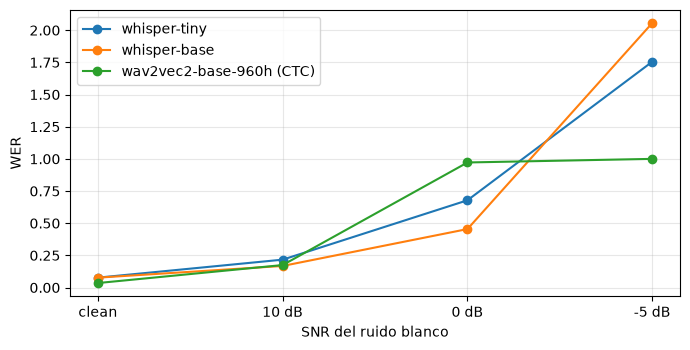

el experimento de ruido tardó 36 s


In [9]:
def add_white(a, snr_db, seed):
    n = np.random.default_rng(seed).standard_normal(len(a)).astype(np.float32)
    return a + n * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10)) / n.std()

def add_babble(a, other, snr_db):
    o = np.resize(other, len(a)); return a + o * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10)) / np.sqrt((o ** 2).mean())

# la copia reducida de LibriSpeech tiene un solo lector, así que las voces que compiten son cadenas de dígitos de FSDD de otros locutores
rb = np.random.default_rng(11)
others = [to16k(np.concatenate([c["audio"] for c in [by_spk[s_][j] for j in rb.integers(len(by_spk[s_]), size=12)]]), 8000) for s_ in ["lucas", "george", "nicolas", "jackson"]]
conds = {"clean": lambda a, i: a,
         "white 10 dB": lambda a, i: add_white(a, 10, i),
         "white 0 dB": lambda a, i: add_white(a, 0, i), "white -5 dB": lambda a, i: add_white(a, -5, i),
         "babble 5 dB": lambda a, i: add_babble(a, others[i % len(others)], 5)}
t0 = time.time(); noise_res = {s: {} for s in SYSTEMS}
for cname, fn_c in conds.items():
    noisy = [fn_c(c["audio"], i) for i, c in enumerate(LS)]
    for s, fn in SYSTEMS.items():
        noise_res[s][cname] = wer(refs_ls, [norm(h) for h in fn(noisy)])
nr = pd.DataFrame(noise_res).T[list(conds)]; display(nr.round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for s in SYSTEMS: ax.plot(range(4), [noise_res[s][c] for c in list(conds)[:4]], "o-", label=s)
ax.set_xticks(range(4)); ax.set_xticklabels(["clean", "10 dB", "0 dB", "-5 dB"]); ax.set_xlabel("SNR del ruido blanco"); ax.set_ylabel("WER"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show(); print("el experimento de ruido tardó %.0f s" % (time.time() - t0))

**Lectura.** Con 10 dB de ruido blanco los tres sistemas se comportan de forma parecida (WER de 16,8 % a 21,7 %). A 0 dB, donde señal y ruido tienen la misma potencia, la imagen cambia: Whisper-base mantiene un 46 % de WER y Whisper-tiny un 68 %, pero wav2vec 2.0, el mejor sistema con habla limpia, llega al 97 %: un reconocedor ajustado con audio limpio se rompe de golpe fuera de sus condiciones, mientras que uno entrenado con 680 000 horas de audio variado se degrada poco a poco. A menos 5 dB nada funciona, y la WER de los modelos Whisper supera el 100 % (1,76 para tiny y 2,06 para base) porque el decodificador **inventa** palabras y se queda en bucles: una WER superior a 1 significa más inserciones que palabras que reconocer. Un segundo hablante a 5 dB perjudica más al modelo CTC (73 % frente a 22 % de Whisper-base), pues no tiene ningún mecanismo para decidir qué voz seguir. Salvedades: el ruido blanco es el más fácil de modelar, 8 clips y un solo sorteo de ruido por condición.

### 3.3 Acentos: los locutores de dígitos

FSDD registra el acento de cada locutor, lo que nos permite hacer una pequeña comprobación honesta de cómo trata un reconocedor de uso general distintos acentos. Para cada locutor construimos 8 secuencias de 4 dígitos aleatorios (200 ms de silencio entre ellos, remuestreadas de 8 kHz a 16 kHz) y las transcribimos con Whisper. Whisper escribe los dígitos como cifras o como palabras, así que normalizamos ambos a palabras y asignamos los homófonos habituales (to/too a two, for a four, won a one, ate a eight, oh a zero) igual para todos. **Son 8 secuencias (32 dígitos) por locutor, una persona por acento**: muestra un patrón, no mide "el acento alemán".

In [10]:
HOMO = {"to": "two", "too": "two", "for": "four", "won": "one", "ate": "eight", "oh": "zero", "o": "zero"}
def norm_digits(t):
    t = re.sub(r"\d", lambda m: " %s " % WORDS[int(m.group())], t.lower())
    return " ".join(HOMO.get(w, w) for w in norm(t).split())

rng_a = np.random.default_rng(3)
acc_audio, acc_ref, acc_spk = [], [], []
for s, cl in sorted(by_spk.items()):
    for _ in range(8):
        pick = [cl[i] for i in rng_a.integers(len(cl), size=4)]
        wav = np.concatenate([np.concatenate([np.zeros(1600, np.float32), c["audio"]]) for c in pick] + [np.zeros(1600, np.float32)])
        acc_audio.append(to16k(wav, 8000)); acc_ref.append(spell([c["digit"] for c in pick])); acc_spk.append(s)
rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    hyp = [norm_digits(h) for h in asr_whisper(name, acc_audio)]
    for s in sorted(by_spk):
        idx = [i for i, x in enumerate(acc_spk) if x == s]
        rows.append(dict(model=name.split("/")[1], speaker=s, accent=ACCENT[s], WER=round(wer([acc_ref[i] for i in idx], [hyp[i] for i in idx]), 3)))
acc = pd.DataFrame(rows); display(acc.pivot(index=["speaker", "accent"], columns="model", values="WER"))
i0 = acc_spk.index("nicolas"); print("ejemplo (nicolas): ref", acc_ref[i0], "| whisper-base oyó:", hyp[i0])

,model,whisper-base,whisper-tiny
speaker,accent,,
george,GRC/Greek,0.062,0.062
jackson,USA/neutral,0.000,0.000
lucas,DEU/German,0.000,0.031
nicolas,BEL/French,0.344,0.469
theo,USA/neutral,0.031,0.031
yweweler,DEU/German,0.000,0.125


ejemplo (nicolas): ref five eight six three | whisper-base oyó: five eight six two one


**Lectura.** Whisper-base transcribe a cinco de los seis locutores con un 0 % a 6 % de errores de palabra, incluidos los dos locutores con acento alemán (0,0 % y 0,0 %) y el griego (6,2 %), pero el locutor franco-belga *nicolas* obtiene un 34 % (tiny: 47 %), por ejemplo `five eight six two one` por `five eight six three`. Whisper-tiny también es peor con *yweweler* (12,5 %). Cada celda son 32 dígitos, así que un error son 3,1 puntos porcentuales y esto son patrones, no mediciones de un acento: cada locutor tiene además un micrófono, una sala y una velocidad de habla distintos, y la etiqueta de acento **no** predijo el orden (el peor locutor no es el que tiene la etiqueta de acento más marcada, y el locutor con acento alemán con el que falló nuestro juguete de la sección 2 se transcribe perfectamente aquí). La conclusión honesta es que la robustez ante la variedad de locutores viene de entrenar con muchos locutores, lo que el modelo grande tiene y nuestro juguete de cinco locutores no, y que la evaluación debe desglosarse por grupos de locutores antes de desplegar un sistema.

### 3.4 Modo de fallo: alucinación con silencio y ruido

El decodificador de Whisper es un modelo de lenguaje condicionado por el audio. Cuando el audio no contiene habla, el lado del modelo de lenguaje puede ganar y producir texto fluido que nadie dijo. Los datos de entrenamiento de Whisper (subtítulos sacados de la web) están llenos de frases de cierre como "Thank you." y "Thanks for watching", y se sabe que el modelo las emite con silencio o música. Probamos cinco entradas de 15 s sin habla, y después una **puerta de actividad de voz** trivial (no ejecutar el reconocedor si la energía está por debajo de un umbral), la más simple de las mitigaciones que se usan en la práctica (las cadenas reales usan un detector de actividad de voz entrenado, umbrales sobre la propia probabilidad de "no hay habla" del modelo y comprobaciones de la tasa de compresión para detectar bucles de repetición).

In [11]:
rs = np.random.default_rng(0); tt = np.arange(15 * 16000) / 16000
nospeech = {"silencio digital": np.zeros(15 * 16000, np.float32),
            "ruido muy bajo (-60 dB)": (rs.standard_normal(15 * 16000) * 1e-3).astype(np.float32),
            "ruido blanco fuerte": (rs.standard_normal(15 * 16000) * 0.1).astype(np.float32),
            "tono de 440 Hz": (0.2 * np.sin(2 * np.pi * 440 * tt)).astype(np.float32),
            "zumbido de red 50/100/150 Hz": (0.1 * (np.sin(2 * np.pi * 50 * tt) + 0.5 * np.sin(2 * np.pi * 100 * tt) + 0.25 * np.sin(2 * np.pi * 150 * tt))).astype(np.float32)}
rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    hyp = asr_whisper(name, list(nospeech.values()))
    for (k, a), h in zip(nospeech.items(), hyp):
        rows.append(dict(model=name.split("/")[1], input=k, rms=round(float(np.sqrt((a ** 2).mean())), 4), output=repr(h[:70])))
display(pd.DataFrame(rows))
GATE = 0.002
print("con una puerta de energía (rms < %.3f significa 'no hay habla, devolver vacío'): el clip de habla pasa: %s | el silencio pasa: %s" % (GATE, np.sqrt((LS[0]["audio"] ** 2).mean()) > GATE, np.sqrt((nospeech["silencio digital"] ** 2).mean()) > GATE))

,model,input,rms,output
0,whisper-tiny,silencio digital,0.0000,'you'
1,whisper-tiny,ruido muy bajo (-60 dB),0.0010,'you'
2,whisper-tiny,ruido blanco fuerte,0.1001,'the'
3,whisper-tiny,tono de 440 Hz,0.1414,'Thank you.'
4,whisper-tiny,zumbido de red 50/100/150 Hz,0.0810,'you'
5,whisper-base,silencio digital,0.0000,'you'
6,whisper-base,ruido muy bajo (-60 dB),0.0010,'you'
7,whisper-base,ruido blanco fuerte,0.1001,"""I'm going to go to the next one."""
8,whisper-base,tono de 440 Hz,0.1414,'I'
9,whisper-base,zumbido de red 50/100/150 Hz,0.0810,'you'


con una puerta de energía (rms < 0.002 significa 'no hay habla, devolver vacío'): el clip de habla pasa: True | el silencio pasa: False


**Lectura.** **Toda** entrada produjo texto, ninguna produjo la cadena vacía que sería lo correcto. El silencio digital, el ruido muy bajo y el zumbido de la red eléctrica se convirtieron en `you` en ambos modelos, un tono de 440 Hz se convirtió en `Thank you.` en el modelo tiny, y el ruido blanco fuerte se convirtió en `the` (tiny) y en una frase completa inventada, `I'm going to go to the next one.` (base). La identificación de idioma muestra la misma elección forzada: con silencio el inglés obtiene solo 0,36 de probabilidad y con ruido blanco el noruego nynorsk obtiene 0,46, de modo que siempre se elige un idioma. La puerta de energía es un arreglo tosco que solo funciona con los casos silenciosos: rechaza el silencio digital, pero el tono, el zumbido y el ruido fuerte tienen mucha más energía que el umbral de 0,002, así que hacen falta un detector de actividad de voz real o umbrales de confianza del modelo. Para cualquier producto que alimente a Whisper con flujos de micrófono, este fallo importa más que un punto de WER: el sistema transcribirá con total seguridad las pausas.

## 4. Síntesis de voz: SpeechT5 y HiFi-GAN

### 4.1 Cómo funciona un TTS neuronal

Convertir texto en habla natural es un problema de **uno a muchos**: una frase puede decirse de infinitas maneras (velocidad, tono, énfasis, voz). Los sistemas modernos se construyen con tres partes:

1. **Front-end de texto**: normalizar el texto (expandir "Dr." y los números, que sorprendentemente es difícil: "1999" es un año, una cantidad o un número de pieza) y convertirlo en símbolos, caracteres o **fonemas** (los sonidos; "though" y "tough" comparten letras pero no sonidos).
2. **Modelo acústico**: convierte los símbolos en un **espectrograma mel**, con un **embedding de locutor** como entrada adicional para elegir la voz. También debe decidir la duración de cada sonido. Los modelos autorregresivos (Tacotron 2, SpeechT5) escriben el espectrograma fotograma a fotograma con atención sobre el texto; los no autorregresivos (FastSpeech 2) predicen las duraciones de forma explícita y escriben todos los fotogramas en paralelo; los modelos tipo VITS integran el vocoder y entrenan todo de extremo a extremo.
3. **Vocoder**: convierte el espectrograma mel en una forma de onda. **HiFi-GAN** (Kong et al., 2020, [arXiv 2010.05646](https://arxiv.org/abs/2010.05646)) es una **red generativa antagónica** convolucional (GAN, ver el [módulo 04 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/04-autoencoders-gans-y-autosupervisado/)) que aumenta la resolución del espectrograma 256 veces con convoluciones transpuestas apiladas y se entrena frente a discriminadores que miran la forma de onda en varios periodos.

**SpeechT5** (Ao et al., 2021, [arXiv 2110.07205](https://arxiv.org/abs/2110.07205)) es un único transformer codificador-decodificador preentrenado con voz y texto y ajustado después para varias tareas; la versión TTS toma caracteres y un **x-vector** de 512 números (un embedding de locutor, sección 6) y escribe fotogramas log-mel de 80 bandas más una señal de "parada". Usamos `microsoft/speecht5_tts` y su vocoder `microsoft/speecht5_hifigan` (licencia MIT, [ficha del modelo](https://huggingface.co/microsoft/speecht5_tts)). Solo habla inglés. Sus vectores de voz proceden del corpus CMU ARCTIC (Kominek y Black, 2004, [artículo](https://www.isca-archive.org/ssw_2004/kominek04b_ssw.pdf), una base de datos de habla libre hecha para investigar el TTS, distribuida sin restricciones), precalculados por Matthijs Hollemans en [`Matthijs/cmu-arctic-xvectors`](https://huggingface.co/datasets/Matthijs/cmu-arctic-xvectors) (licencia MIT). A partir de ahora cada voz de este cuaderno es **una de estas 7 voces del corpus o una mezcla sintética de ellas**; nunca imitamos a una persona que no haya publicado una voz para este fin.

SpeechT5: 144 M parameters | HiFi-GAN: 12.7 M parameters


{'awb': 'hombre escocés (1138 frases)', 'bdl': 'hombre EE. UU. (1133 frases)', 'clb': 'mujer EE. UU. (1132 frases)', 'jmk': 'hombre canadiense (1132 frases)', 'ksp': 'hombre indio (1132 frases)', 'rms': 'hombre EE. UU. (1132 frases)', 'slt': 'mujer EE. UU. (1132 frases)'}


'The library opens at nine and closes at five on weekdays.'
 -> mel (238, 80), forma de onda de 3.81 s de audio en 1.96 s de cálculo (factor de tiempo real 0.51; por debajo de 1 es más rápido que el tiempo real)


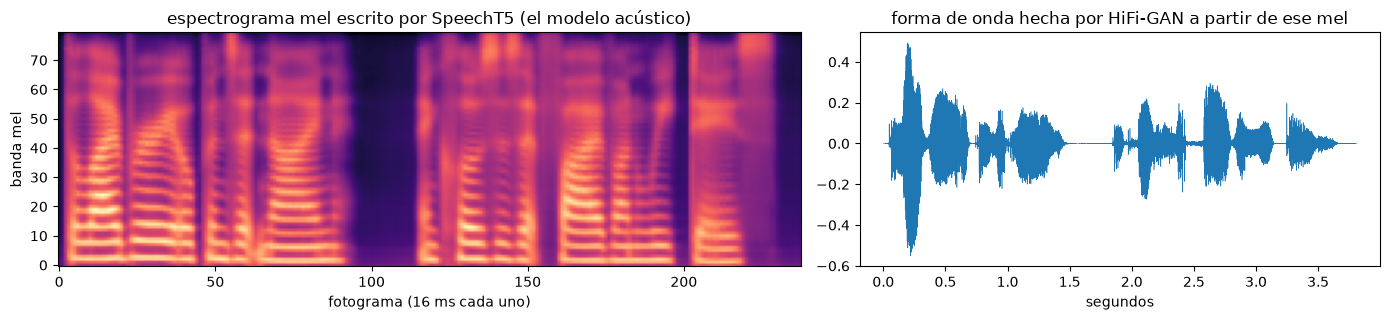

voz 'slt' (mujer de EE. UU., x-vector de CMU ARCTIC):


In [12]:
from transformers import SpeechT5Processor, SpeechT5ForTextToSpeech, SpeechT5HifiGan
t5p = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
t5 = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts").eval()
hifi = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").eval()
print("SpeechT5: %.0f M parameters | HiFi-GAN: %.1f M parameters" % (sum(p.numel() for p in t5.parameters()) / 1e6, sum(p.numel() for p in hifi.parameters()) / 1e6))

# las 7 voces del corpus: promediar los x-vectors de todas las frases de un locutor y renormalizar a longitud unidad
xz = zipfile.ZipFile(hf_hub_download("Matthijs/cmu-arctic-xvectors", "spkrec-xvect.zip", repo_type="dataset"))
acc_v = {}
for n in xz.namelist():
    m = re.search(r"cmu_us_(\w+)_arctic", n)
    if m and n.endswith(".npy"): acc_v.setdefault(m.group(1), []).append(np.load(io.BytesIO(xz.read(n))))
VOICE = {k: F.normalize(torch.tensor(np.mean([v / np.linalg.norm(v) for v in vs], 0)), dim=-1) for k, vs in acc_v.items()}
DESC = {"bdl": "hombre EE. UU.", "slt": "mujer EE. UU.", "jmk": "hombre canadiense", "awb": "hombre escocés", "rms": "hombre EE. UU.", "clb": "mujer EE. UU.", "ksp": "hombre indio"}
print({k: "%s (%d frases)" % (DESC[k], len(v)) for k, v in sorted(acc_v.items())})

@torch.no_grad()
def speak(text, xvec, seed=0, return_mel=False):
    torch.manual_seed(seed)                                   # el prenet del decodificador de SpeechT5 usa dropout también en inferencia
    ids = t5p(text=text, return_tensors="pt")["input_ids"]
    mel = t5.generate_speech(ids, xvec.reshape(1, -1))        # sin vocoder: el espectrograma mel, de forma (fotogramas, 80)
    wav = hifi(mel).squeeze().numpy()                         # el vocoder: mel -> forma de onda a 16 kHz
    return (mel, wav) if return_mel else wav

SENT = ["The library opens at nine and closes at five on weekdays.",
        "Please remember to bring a warm jacket because the evening will be cold.",
        "She planted three tomato seeds in a small pot near the kitchen window.",
        "A neural network learns by adjusting its weights to reduce an error.",
        "The train to the coast leaves from the second platform every hour.",
        "He painted the old fence blue and the children helped with the gate.",
        "Scientists measured the temperature of the lake at different depths.",
        "Fresh bread and strong coffee were waiting on the table this morning."]
t0 = time.time(); mel, wav = speak(SENT[0], VOICE["slt"], return_mel=True); dt = time.time() - t0
print("'%s'\n -> mel %s, forma de onda de %.2f s de audio en %.2f s de cálculo (factor de tiempo real %.2f; por debajo de 1 es más rápido que el tiempo real)" % (SENT[0], tuple(mel.shape), len(wav) / 16000, dt, dt / (len(wav) / 16000)))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.3), gridspec_kw={"width_ratios": [2, 1.4]})
ax[0].imshow(mel.numpy().T, origin="lower", aspect="auto", cmap="magma"); ax[0].set_title("espectrograma mel escrito por SpeechT5 (el modelo acústico)"); ax[0].set_xlabel("fotograma (16 ms cada uno)"); ax[0].set_ylabel("banda mel")
ax[1].plot(np.arange(len(wav)) / 16000, wav, lw=0.4); ax[1].set_title("forma de onda hecha por HiFi-GAN a partir de ese mel"); ax[1].set_xlabel("segundos")
plt.tight_layout(); plt.show()
play(wav, 16000, "voz 'slt' (mujer de EE. UU., x-vector de CMU ARCTIC):")

### 4.2 Evaluación sin escuchar: WER de ida y vuelta

Las pruebas subjetivas de escucha (puntuación media de opinión, MOS) son el patrón oro para la naturalidad pero necesitan personas. Un sustituto barato de la **inteligibilidad** es el **viaje de ida y vuelta**: sintetizar una frase, transcribirla con un sistema ASR independiente y calcular la WER respecto al texto original. Si un buen reconocedor no entiende el habla sintética, probablemente las personas también tengan dificultades. Salvedades: el reconocedor tiene un modelo de lenguaje potente y puede "reparar" habla ligeramente incorrecta, y el viaje de ida y vuelta no dice nada de la naturalidad, la emoción o la calidad de la voz. Usamos Whisper-base como juez con 8 frases en una voz y 4 en otra, añadimos un control con un **vector de locutor aleatorio** (una voz que no existe, 3 frases) y probamos después cuatro frases elegidas por ser difíciles para un front-end de texto: números, una hora, una abreviatura, topónimos raros y un trabalenguas.

In [13]:
SPEECH = {}
def say(voice, i):                                     # con memoria: nombre de la voz, índice de la frase
    if (voice, i) not in SPEECH: SPEECH[(voice, i)] = speak(SENT[i], VOICE[voice], seed=i)
    return SPEECH[(voice, i)]

t0 = time.time(); rt_rows = {}
for v in ["slt", "bdl"]:
    nS = len(SENT) if v == "slt" else 4
    hyp = asr_whisper("openai/whisper-base", [say(v, i) for i in range(nS)])
    rt_rows["voz %s (%s), %d frases" % (v, DESC[v], nS)] = wer([norm(x) for x in SENT[:nS]], [norm(h) for h in hyp])
g = torch.Generator().manual_seed(0); RAND_V = F.normalize(torch.randn(512, generator=g), dim=-1)
hyp = asr_whisper("openai/whisper-base", [speak(SENT[i], RAND_V, seed=i) for i in range(3)])
rt_rows["vector de locutor aleatorio (primeras 3 frases)"] = wer([norm(s) for s in SENT[:3]], [norm(h) for h in hyp])
hyp = asr_whisper("openai/whisper-tiny", [say("slt", i) for i in range(len(SENT))])
rt_rows["voz slt, juzgada por whisper-tiny"] = wer([norm(s) for s in SENT], [norm(h) for h in hyp])
print(pd.Series(rt_rows, name="WER de ida y vuelta").round(3).to_string())
print("síntesis + reconocimiento tardaron %.0f s" % (time.time() - t0))

HARD = ["Doctor Nguyen arrived at 4:30 on March 3rd.", "The GPU has 24 GB of VRAM.", "Reykjavik and Ljubljana are both capital cities.", "She sells sea shells by the sea shore."]
heard = asr_whisper("openai/whisper-base", [speak(h, VOICE["slt"], seed=7) for h in HARD])
for h, o in zip(HARD, heard): print("\ntexto :", h, "\noído :", o)
play(say("bdl", 1), 16000, "voz 'bdl' (hombre de EE. UU.): " + SENT[1])

voz slt (mujer EE. UU.), 8 frases                  0.000
voz bdl (hombre EE. UU.), 4 frases                 0.041
vector de locutor aleatorio (primeras 3 frases)    0.054
voz slt, juzgada por whisper-tiny                  0.010
síntesis + reconocimiento tardaron 34 s



texto : Doctor Nguyen arrived at 4:30 on March 3rd. 
oído : Dr. Glyan arrived at Unmarch-Eard.

texto : The GPU has 24 GB of VRAM. 
oído : The goo has G of RAM.

texto : Reykjavik and Ljubljana are both capital cities. 
oído : Rakeshavik and Najib Aljana are both capital cities.

texto : She sells sea shells by the sea shore. 
oído : She sells seashells by the seashore.
voz 'bdl' (hombre de EE. UU.): Please remember to bring a warm jacket because the evening will be cold.


**Lectura.** El habla sintética es muy inteligible para un reconocedor independiente: WER de ida y vuelta del 0,0 % para la voz *slt* (8 frases), del 4,1 % para la voz *bdl* (4 frases, unas dos palabras) y del 1,0 % cuando Whisper-tiny juzga a *slt*, así que las diferencias entre las voces están dentro del ruido. Un vector de locutor aleatorio, una voz que no existe, da un 5,4 % en las tres frases con las que se probó: el modelo acústico se las arregla con un vector fuera de distribución pero algo peor. Las frases que ponen a prueba el **front-end de texto** fallan de forma visible: `4:30` y `March 3rd` se convierten en `Unmarch-Eard`, `GPU` y `24 GB` en `goo` y `G`, y los topónimos poco comunes salen deformados, mientras que el trabalenguas sale bien. Parte de eso puede deberse a la dificultad del juez con nombres raros, así que un viaje de ida y vuelta encuentra problemas pero no dice qué etapa tiene la culpa. Este modelo lee caracteres, de modo que en un sistema real los números, las fechas y las abreviaturas deben expandirse a palabras antes de sintetizar, y los nombres raros necesitan un diccionario de pronunciación. Velocidad: unos 2,1 s de cálculo para 3,8 s de audio con 2 hilos (factor de tiempo real 0,55, incluida algo de sobrecarga de la primera llamada). Salvedad: pocas frases y un solo juez; la WER de ida y vuelta no dice nada sobre la naturalidad ni la prosodia.

## 5. Traducción de voz a voz como cascada

La forma más simple de traducir habla es encadenar los tres sistemas que ya tenemos: **ASR** (voz a texto de origen), luego **traducción automática** (MT, de texto de origen a texto de destino) y luego **TTS** (texto de destino a voz). Sus puntos fuertes son la modularidad y poder inspeccionar y arreglar cada etapa; sus puntos débiles son que los **errores se acumulan** (una palabra mal oída se traduce con total seguridad) y que la prosodia, la emoción y la identidad del hablante se pierden en el cuello de botella del texto. Los modelos *directos* más nuevos se saltan el texto; el propio Whisper difumina la frontera porque su decodificador puede producir texto en inglés directamente a partir de habla extranjera.

Dos piezas nuevas, ambas abiertas:

* **Opus-MT** (Tiedemann y Thottingal, 2020, [ACL Anthology](https://aclanthology.org/2020.eamt-1.61/)): pequeños modelos de traducción transformer Marian, uno por par de idiomas, entrenados con los corpus paralelos OPUS; usamos `Helsinki-NLP/opus-mt-en-{es,fr,de}` y `opus-mt-es-en` (Apache 2.0 en las fichas de los modelos, CC BY 4.0 para en-de; [ficha del modelo](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)).
* **MMS-TTS** (Pratap et al., 2023, [arXiv 2305.13516](https://arxiv.org/abs/2305.13516)): modelos TTS de una sola voz basados en VITS para más de 1100 idiomas; usamos `facebook/mms-tts-{eng,spa,fra,deu}` (CC BY-NC 4.0, no comercial; [ficha del modelo](https://huggingface.co/facebook/mms-tts-spa)).

Primero fabricamos los clips en otros idiomas: traducimos cuatro de nuestras frases al español, francés y alemán con Opus-MT y las leemos con MMS-TTS. Son voces sintéticas, lo cual es una limitación (audio limpio y uniforme), pero nos dan referencias conocidas en tres idiomas sin grabaciones de personas reales.

In [14]:
from transformers import MarianMTModel, MarianTokenizer, VitsModel, AutoTokenizer
_M, _V = {}, {}
@torch.no_grad()
def translate(texts, src, tgt):
    name = "Helsinki-NLP/opus-mt-%s-%s" % (src, tgt)
    if name not in _M: _M[name] = (MarianTokenizer.from_pretrained(name), MarianMTModel.from_pretrained(name).eval())
    tok, m = _M[name]
    return tok.batch_decode(m.generate(**tok(texts, return_tensors="pt", padding=True), num_beams=4, max_new_tokens=120), skip_special_tokens=True)

@torch.no_grad()
def mms(text, lang, seed=0):                              # idioma: eng, spa, fra, deu
    if lang not in _V: _V[lang] = (AutoTokenizer.from_pretrained("facebook/mms-tts-" + lang), VitsModel.from_pretrained("facebook/mms-tts-" + lang).eval())
    tok, m = _V[lang]; torch.manual_seed(seed)
    return m(**tok(text, return_tensors="pt")).waveform[0].numpy()

N5 = 4; LANGS = {"es": "spa", "fr": "fra", "de": "deu"}
t0 = time.time(); text_tr, clips = {}, {"en": [say("slt", i) for i in range(N5)]}
for l, l3 in LANGS.items():
    text_tr[l] = translate(SENT[:N5], "en", l)
    clips[l] = [mms(t, l3, seed=i) for i, t in enumerate(text_tr[l])]
print("fabricar 12 clips en otros idiomas tardó %.0f s" % (time.time() - t0))
for l in LANGS: print(l, "|", text_tr[l][0])
play(clips["es"][0], 16000, "clip en español (MMS-TTS):")

# ---- identificación de idioma: el primer paso del decodificador de Whisper es una distribución sobre tokens de idioma ----
@torch.no_grad()
def lang_probs(name, a, top=2):
    proc, m = whisper(name)
    f = proc(a, sampling_rate=16000, return_tensors="pt").input_features
    sot = proc.tokenizer.convert_tokens_to_ids("<|startoftranscript|>")
    lg = m(input_features=f, decoder_input_ids=torch.tensor([[sot]])).logits[0, -1]
    ids = m.generation_config.lang_to_id
    pr = lg[list(ids.values())].softmax(-1); names = [k.strip("<|>") for k in ids]
    return [(names[i], float(pr[i])) for i in pr.argsort(descending=True)[:top]]

rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    for l, cl in clips.items():
        for i, a in enumerate(cl):
            (p1, q1), (p2, q2) = lang_probs(name, a)
            rows.append(dict(model=name.split("/")[1], true=l, predicted=p1, confidence=q1, second=p2, ok=(p1 == l)))
lid = pd.DataFrame(rows)
display(lid.groupby(["model", "true"]).agg(accuracy=("ok", "mean"), mean_confidence=("confidence", "mean")).round(2).unstack(0))
for k in ["silencio digital", "ruido blanco fuerte"]:
    print("identificación de idioma en %-18s ->" % k, [(p, round(q, 2)) for p, q in lang_probs("openai/whisper-base", nospeech[k])])

fabricar 12 clips en otros idiomas tardó 15 s
es | La biblioteca abre a las nueve y cierra a las cinco de la semana.
fr | La bibliothèque ouvre à neuf heures et ferme à cinq heures en semaine.
de | Die Bibliothek öffnet um neun Uhr und schließt an Wochentagen um fünf Uhr.
clip en español (MMS-TTS):


accuracy              mean_confidence             
model whisper-base whisper-tiny    whisper-base whisper-tiny
true                                                        
de             1.0          1.0            1.00         0.99
en             1.0          1.0            1.00         1.00
es             1.0          1.0            0.99         0.97
fr             1.0          1.0            1.00         0.99

identificación de idioma en silencio digital   -> [('en', 0.36), ('cy', 0.21)]
identificación de idioma en ruido blanco fuerte -> [('nn', 0.46), ('en', 0.25)]


**Lectura.** Whisper identifica correctamente el idioma de los 16 clips, con ambos tamaños de modelo (inglés, español, francés y alemán, 4 clips cada uno) y con una confianza media entre 0,97 y 1,00. Este es el caso fácil: audio limpio de voces sintéticas, frases largas y cuatro idiomas muy distintos; el habla con idiomas mezclados, las emisiones cortas, los idiomas próximos (español y portugués, noruego y danés) y el ruido son más difíciles, y los resultados con silencio y ruido de antes muestran que el modelo no tiene una opción "ningún idioma". Para **traducir al inglés**, Whisper-base da una WER del 43 % (español), 61 % (francés) y 76 % (alemán) frente a las frases originales en inglés, y Whisper-small del 33 %, 37 % y 37 %. Estas cifras incluyen la pérdida de la primera traducción automática (los originales pasaron de inglés a X antes de sintetizarse, de modo que incluso un sistema perfecto tiene un suelo de error, medido más abajo en torno al 22 % para el español), y 4 frases por idioma es una muestra pequeña, pero el orden es claro: el modelo mayor es mucho mejor, y la tarea de traducción directa de un Whisper pequeño es débil.

### 5.1 Traducir al inglés: la tarea propia de Whisper frente a la cascada

A Whisper se le puede pedir `task="translate"` y escribe texto en inglés directamente a partir de habla extranjera. Lo comparamos con la **cascada** explícita sobre los clips en español, puntuando contra la frase original en inglés con la que empezó la cadena (una retrotraducción: el inglés original pasó por traducción automática, síntesis de voz y ahora reconocimiento más traducción otra vez, así que incluso un sistema perfecto pierde algo en la primera traducción automática). Las etapas son:

* **A**: voz en inglés (SpeechT5, voz slt);
* **B**: transcripción de A con Whisper-base;
* **C**: texto en español, traducción de B con Opus-MT;
* **D**: voz en español, MMS-TTS de C. *Esta es la salida de un traductor de voz a voz*;
* **E**: transcripción en español de D con Whisper-small (¿es inteligible la voz de salida?);
* **F**: texto en inglés, traducción de E con Opus-MT (¿sobrevive el significado?).

Líneas de base: un viaje de ida y vuelta **solo de texto** (inglés a español a inglés sin voz alguna) aísla el coste de la traducción automática, y la tarea de traducción directa de Whisper sobre D.

model,whisper-base,whisper-small
language,,
de,0.755,0.367
es,0.429,0.327
fr,0.612,0.367


E frente a C: tasa de error de palabras del ASR en español sobre la voz española generada = 0.113
B  solo ASR (texto en inglés frente a la referencia)    0.000
C->F ida y vuelta solo de texto, sin voz                0.224
F  cascada completa, de vuelta al inglés                0.224
traducción de Whisper (base) sobre D                    0.429
traducción de Whisper (small) sobre D                   0.327

A  (voz) ->  B: Please remember to bring a warm jacket because the evening will be cold. 
C (español) : Por favor, recuerde traer una chaqueta caliente porque la noche estará fría. 
E (oído)    : Por favor recuerde traer una chaqueta caliente porque la noche estará fría. 
F (inglés)  : Please remember to bring a warm jacket because the night will be cold. 
referencia  : Please remember to bring a warm jacket because the evening will be cold.

A  (voz) ->  B: A neural network learns by adjusting its weights to reduce an error. 
C (español) : Una red neuronal aprende ajustando sus pesos

la cascada tardó 29 s


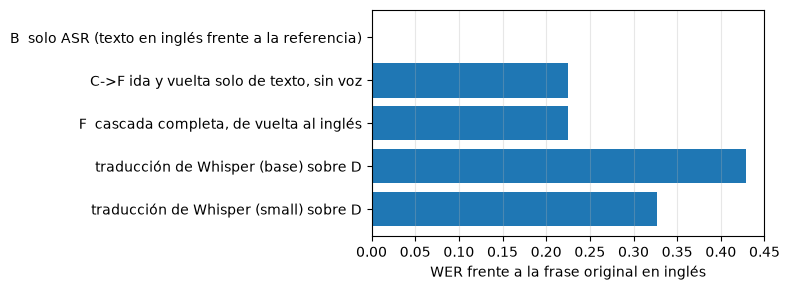

In [15]:
t0 = time.time(); ref5 = [norm(s) for s in SENT[:N5]]
# tarea de traducción de whisper, los tres idiomas, dos tamaños de modelo
rows = []
for name in ["openai/whisper-base", "openai/whisper-small"]:
    for l in LANGS:
        hyp = asr_whisper(name, clips[l], language=l, task="translate")
        rows.append(dict(model=name.split("/")[1], language=l, WER_vs_original_English=round(wer(ref5, [norm(h) for h in hyp]), 3)))
direct = pd.DataFrame(rows).pivot(index="language", columns="model", values="WER_vs_original_English"); display(direct)

# la cascada A -> F
B = asr_whisper("openai/whisper-base", clips["en"])
C = translate(B, "en", "es")
D = [mms(t, "spa", seed=i) for i, t in enumerate(C)]
E = asr_whisper("openai/whisper-small", D, language="es")
Fb = translate(E, "es", "en")
text_only = translate(translate(SENT[:N5], "en", "es"), "es", "en")
stage = {"B  solo ASR (texto en inglés frente a la referencia)": wer(ref5, [norm(x) for x in B]),
         "C->F ida y vuelta solo de texto, sin voz": wer(ref5, [norm(x) for x in text_only]),
         "F  cascada completa, de vuelta al inglés": wer(ref5, [norm(x) for x in Fb]),
         "traducción de Whisper (base) sobre D": wer(ref5, [norm(x) for x in asr_whisper("openai/whisper-base", D, language="es", task="translate")]),
         "traducción de Whisper (small) sobre D": wer(ref5, [norm(x) for x in asr_whisper("openai/whisper-small", D, language="es", task="translate")])}
asr_es = wer([norm(x) for x in C], [norm(x) for x in E])
print("E frente a C: tasa de error de palabras del ASR en español sobre la voz española generada = %.3f" % asr_es)
print(pd.Series(stage, name="WER frente al inglés original").round(3).to_string())
for i in [1, 3]:
    print("\nA  (voz) ->  B:", B[i], "\nC (español) :", C[i], "\nE (oído)    :", E[i], "\nF (inglés)  :", Fb[i], "\nreferencia  :", SENT[i])
play(D[1], 16000, "D: la voz traducida al español de la frase 2:")
print("la cascada tardó %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(figsize=(8, 3)); ax.barh(list(stage)[::-1], list(stage.values())[::-1], color="C0"); ax.set_xlabel("WER frente a la frase original en inglés"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Lectura.** La cascada funciona de extremo a extremo con estas cuatro frases. La etapa B (Whisper-base sobre la voz en inglés) es exacta (WER 0,0 %); el camino completo voz en inglés, texto en español, voz en español, transcripción en español, texto en inglés devuelve un texto a un 22,4 % del original, y el viaje de ida y vuelta **solo de texto**, sin voz, también es del 22,4 %: en esta muestra casi toda la pérdida está en la traducción automática (el mismo significado dicho con otras palabras, como `evening` que pasa a `night`) y las etapas de voz añaden poco en total, aunque el reconocedor de español oyó mal la voz española generada con una tasa de error de palabras del 11,3 % en las cuatro frases (`red neuronada pre-deajustando` por `red neuronal aprende ajustando`), lo que después se propagó al inglés (`A neuron network pre-deadjustable its weights`): la acumulación de errores típica de las cascadas. Que ambos totales coincidan es en parte casualidad (en cada caso fallan palabras distintas); con cuatro frases no debe leerse nada más fino. La tarea de traducción propia de Whisper aplicada a la voz española generada es claramente peor que la cascada aquí (42,9 % para base y 32,7 % para small frente a 22,4 %), por lo que las cascadas siguen siendo la referencia práctica.

## 6. Embeddings de locutor, similitud y clonación de voz

### 6.1 Qué es un embedding de locutor

Un **embedding de locutor** convierte un clip de cualquier duración en un vector fijo tal que los clips de la misma persona quedan cerca y los de personas distintas lejos, sea lo que sea lo que se diga. Los **x-vectors** (Snyder et al., 2018) agrupan rasgos a nivel de fotograma a lo largo del tiempo en un único vector con una capa de estadísticos. **ECAPA-TDNN** (Desplanques et al., 2020, [arXiv 2005.07143](https://arxiv.org/abs/2005.07143)) los mejora con atención por canal, rasgos a varias escalas y agregación entre capas, y se entrena con una pérdida de margen angular con miles de locutores (VoxCeleb). Usamos el modelo preentrenado de SpeechBrain [`speechbrain/spkrec-ecapa-voxceleb`](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb) (192 números por clip, licencia Apache 2.0 para el código y el modelo; los datos de entrenamiento de VoxCeleb tienen sus propios términos) y comparamos clips con la **similitud del coseno**. Dos papeles, dados deliberadamente a modelos **distintos** para que la prueba no sea circular:

* ECAPA es el **juez**: ¿cuánto se parecen dos voces?
* el extractor de x-vectors [`speechbrain/spkrec-xvect-voxceleb`](https://huggingface.co/speechbrain/spkrec-xvect-voxceleb) (512 números, Apache 2.0) es el modelo con el que se hicieron las voces de SpeechT5, así que es el modelo de **registro** que convierte un clip de referencia en un vector de voz para el TTS.

Primero una comprobación de cordura con habla **real**: ¿sabe ECAPA distinguir locutores? Con los seis locutores de FSDD (que publicaron sus grabaciones abiertamente; solo calculamos similitudes, y cada clip es una sola palabra de 0,5 s, un caso difícil). La copia de LibriSpeech que usamos tiene un solo lector, así que no sirve para esta prueba.

Failed to detect torchaudio major version; unsure how to check your setup. We recommend that you keep torchaudio up-to-date.


Failed to detect torchaudio major version; unsure how to check your setup. We recommend that you keep torchaudio up-to-date.


FSDD: 120 clips de 6 locutores, 1140 pares del mismo locutor, 6000 pares de locutores distintos
coseno medio mismo locutor 0.51 | locutores distintos 0.19 | tasa de error igual 7.4 % con umbral 0.34
identificación de locutor a partir de un dígito de 0,5 s (dejando uno fuera, 6 locutores, azar 17 %): 100 %
calcular los embeddings tardó 3 s


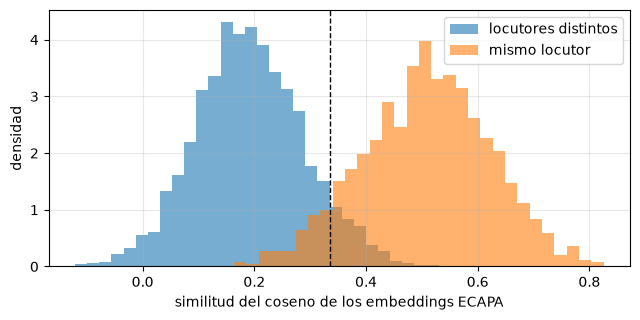

In [16]:
try:
    import torchaudio                                   # en Colab es el real, preinstalado junto a torch
except Exception:                                       # si falta torchaudio o no coincide: SpeechBrain solo necesita que el módulo exista para la inferencia
    import sys, types
    _ta = types.ModuleType("torchaudio"); _ta.__version__ = "0.0"
    _ta.list_audio_backends = lambda: []; _ta.set_audio_backend = lambda *a, **k: None; _ta.get_audio_backend = lambda: None
    sys.modules["torchaudio"] = _ta
from speechbrain.inference.speaker import EncoderClassifier
from sklearn.metrics import roc_curve
ecapa = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb", savedir=CACHE + "/ecapa", run_opts={"device": "cpu"})
xvec_net = EncoderClassifier.from_hparams(source="speechbrain/spkrec-xvect-voxceleb", savedir=CACHE + "/xvect", run_opts={"device": "cpu"})

@torch.no_grad()
def emb(model, a): return F.normalize(model.encode_batch(torch.tensor(np.asarray(a, dtype=np.float32))[None]).reshape(-1), dim=-1)

# --- FSDD: seis locutores, clips de una palabra a 8 kHz (la copia de LibriSpeech tiene un lector, así que no puede probar la separación de locutores) ---
t0 = time.time(); sp6 = sorted(by_spk); E_f, y_f = [], []
for j, s_ in enumerate(sp6):
    for c in by_spk[s_][:20]: E_f.append(emb(ecapa, to16k(c["audio"], 8000))); y_f.append(j)
E_f = torch.stack(E_f); y_f = np.array(y_f)
S = (E_f @ E_f.T).numpy(); iu = np.triu_indices(len(y_f), 1)
same = y_f[iu[0]] == y_f[iu[1]]; sims = S[iu]
fpr, tpr, thr = roc_curve(same, sims); fnr = 1 - tpr; k = np.argmin(np.abs(fpr - fnr)); eer = (fpr[k] + fnr[k]) / 2
print("FSDD: %d clips de 6 locutores, %d pares del mismo locutor, %d pares de locutores distintos" % (len(y_f), same.sum(), (~same).sum()))
print("coseno medio mismo locutor %.2f | locutores distintos %.2f | tasa de error igual %.1f %% con umbral %.2f" % (sims[same].mean(), sims[~same].mean(), 100 * eer, thr[k]))
hits = 0
for i in range(len(y_f)):
    cent = torch.stack([F.normalize(E_f[(y_f == j) & (np.arange(len(y_f)) != i)].mean(0), dim=-1) for j in range(6)])
    hits += int((cent @ E_f[i]).argmax()) == y_f[i]
print("identificación de locutor a partir de un dígito de 0,5 s (dejando uno fuera, 6 locutores, azar 17 %%): %.0f %%" % (100 * hits / len(y_f)))
print("calcular los embeddings tardó %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.hist(sims[~same], bins=30, alpha=0.6, density=True, label="locutores distintos"); ax.hist(sims[same], bins=30, alpha=0.6, density=True, label="mismo locutor")
ax.axvline(thr[k], c="k", ls="--", lw=1); ax.set_xlabel("similitud del coseno de los embeddings ECAPA"); ax.set_ylabel("densidad"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lectura.** A partir de un solo dígito de medio segundo, ECAPA identifica cuál de los seis locutores de FSDD está hablando el 100 % de las veces (120 clips, el azar es el 17 %), la similitud media es 0,51 para el mismo locutor y 0,19 para locutores distintos, y la tasa de error igual (el umbral en el que las falsas aceptaciones y los falsos rechazos son igual de frecuentes) es del 7,4 %. Hay que tener cuidado con la parte fácil de este resultado: cada locutor de FSDD se grabó en una sola configuración, así que el micrófono y la sala identifican al locutor tanto como la voz, y seis locutores es una prueba pequeña. Los sistemas reales de verificación de locutor se evalúan con miles de locutores en condiciones variadas; sus tasas de error son más altas que esta y suben mucho con habla corta, ruidosa o emocional.

### 6.2 Condicionar un TTS a un embedding de locutor y clonar a partir de una referencia

SpeechT5 toma su voz de un vector de 512 números. Dos experimentos, **ambos solo con voces sintéticas**:

1. **¿Suenan cinco de las voces del corpus como cinco locutores distintos para un juez independiente?** Sintetizamos tres frases por voz y dejamos que ECAPA identifique la voz de cada clip a partir de las *otras* frases (dejando una frase fuera): una prueba justa de que el embedding lleva la identidad y no el texto.
2. **Clonar a partir de una referencia.** Para cada una de las cinco voces tomamos **un clip sintético de 3 a 4 segundos** como "grabación de referencia", lo registramos con el extractor de x-vectors para obtener un vector de voz, pedimos a SpeechT5 que diga una frase **nueva** con ese vector y comprobamos si el juez ECAPA asigna el resultado a la voz correcta. Dos controles: el *oráculo* (SpeechT5 con el vector de voz verdadero, lo mejor que puede hacer este TTS) y un vector *aleatorio*. Los centroides del juez se construyen solo con las otras dos frases, nunca con el clip de referencia.

ECAPA identifica la voz sintética de una frase reservada: 15 de 15 (azar 20 %)
coseno medio, misma voz y frases distintas: 0.85 | voces distintas: 0.37


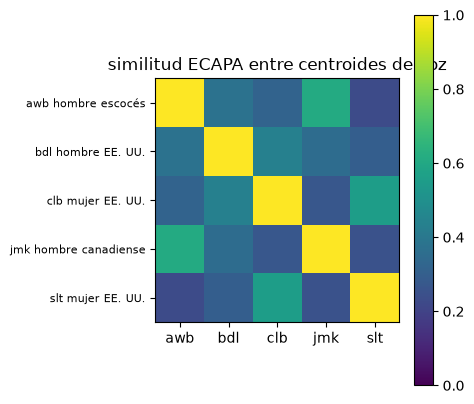

,similarity_to_target,best_other_voice,identified_correctly,xvector_cosine_to_true
kind,,,,
clone,0.83,0.53,5,0.98
oracle,0.88,0.52,5,1.00


control con vector aleatorio: la voz más parecida es clb con coseno 0.53 (no es nadie)


,voice,sim_target,sim_best_other,correct,xvec_cos_to_true
0,awb,0.84,0.54,True,0.98
1,bdl,0.85,0.41,True,0.97
2,clb,0.90,0.52,True,0.98
3,jmk,0.77,0.59,True,0.97
4,slt,0.80,0.58,True,0.98


el experimento de clonación tardó 45 s
voz objetivo jmk (hombre canadiense):


clon hecho a partir de un clip de referencia de jmk:


In [17]:
t0 = time.time(); VN = ["awb", "bdl", "clb", "jmk", "slt"]                                      # cinco de las siete voces del corpus, para acortar la ejecución
EV = {v: [emb(ecapa, say(v, i)) for i in range(3)] for v in VN}                    # 5 voces x 3 frases
cent = {v: F.normalize(torch.stack(EV[v]).mean(0), dim=-1) for v in VN}
# 1) identificación de la voz dejando una frase fuera
hits = 0
for v in VN:
    for i in range(3):
        c_ = torch.stack([F.normalize(torch.stack([EV[u][j] for j in range(3) if j != i]).mean(0), dim=-1) for u in VN])
        hits += int((c_ @ EV[v][i]).argmax()) == VN.index(v)
print("ECAPA identifica la voz sintética de una frase reservada: %d de %d (azar %.0f %%)" % (hits, 3 * len(VN), 100 / len(VN)))
M = torch.stack([cent[v] for v in VN]); SIM = (M @ M.T).numpy()
within = np.mean([float(EV[v][i] @ EV[v][j]) for v in VN for i in range(3) for j in range(i + 1, 3)])
print("coseno medio, misma voz y frases distintas: %.2f | voces distintas: %.2f" % (within, SIM[~np.eye(len(VN), dtype=bool)].mean()))
fig, ax = plt.subplots(figsize=(4.8, 4.2)); im = ax.imshow(SIM, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(VN))); ax.set_yticks(range(len(VN))); ax.set_xticklabels(["%s" % v for v in VN]); ax.set_yticklabels(["%s %s" % (v, DESC[v]) for v in VN], fontsize=8)
ax.set_title("similitud ECAPA entre centroides de voz"); plt.colorbar(im); plt.tight_layout(); plt.show()

# 2) clonación: clip de referencia (frase 0) -> x-vector -> frase nueva 3
rows = []; cl_audio = {}
for v in VN:
    ref_clip = say(v, 0)
    xv = emb(xvec_net, ref_clip)                                                    # registro: vector de voz de 512 dimensiones
    clone = speak(SENT[3], xv, seed=3); oracle = say(v, 3); cl_audio[v] = clone
    # centroides del juez solo con las frases 1 y 2 (se excluye la frase de referencia 0)
    cents = torch.stack([F.normalize(torch.stack([EV[u][1], EV[u][2]]).mean(0), dim=-1) for u in VN])
    for kind, a in [("clone", clone), ("oracle", oracle)]:
        s_ = cents @ emb(ecapa, a)
        rows.append(dict(voice=v, kind=kind, sim_target=float(s_[VN.index(v)]), sim_best_other=float(np.delete(s_.numpy(), VN.index(v)).max()), correct=int(s_.argmax()) == VN.index(v)))
    rows[-2]["xvec_cos_to_true"] = float(xv @ VOICE[v]); rows[-1]["xvec_cos_to_true"] = 1.0
rnd = speak(SENT[3], RAND_V, seed=3); s_r = torch.stack([F.normalize(torch.stack([EV[u][1], EV[u][2]]).mean(0), dim=-1) for u in VN]) @ emb(ecapa, rnd)
cl = pd.DataFrame(rows)
display(cl.groupby("kind").agg(similarity_to_target=("sim_target", "mean"), best_other_voice=("sim_best_other", "mean"), identified_correctly=("correct", "sum"), xvector_cosine_to_true=("xvec_cos_to_true", "mean")).round(2))
print("control con vector aleatorio: la voz más parecida es %s con coseno %.2f (no es nadie)" % (VN[int(s_r.argmax())], float(s_r.max())))
display(cl[cl.kind == "clone"][["voice", "sim_target", "sim_best_other", "correct", "xvec_cos_to_true"]].round(2).reset_index(drop=True))
print("el experimento de clonación tardó %.0f s" % (time.time() - t0))
play(say("jmk", 3), 16000, "voz objetivo jmk (hombre canadiense):"); play(cl_audio["jmk"], 16000, "clon hecho a partir de un clip de referencia de jmk:")

**Lectura.** El embedding sí lleva identidad de voz. ECAPA identifica la voz de los 15 clips sintéticos reservados (el azar es el 20 %); la similitud media es 0,85 entre frases distintas de la misma voz y 0,37 entre voces distintas. **Clonar a partir de un clip de referencia funciona en este entorno**: para las 5 voces el clon queda más cerca de su objetivo (similitud 0,83 frente a 0,53 de la mejor otra voz), el x-vector registrado a partir de la referencia tiene un coseno de 0,98 con el vector de voz verdadero, y el oráculo, que usa el vector verdadero, puntúa 0,88, de modo que el registro a partir de un clip de 3 a 4 segundos pierde unos 0,05 de la similitud alcanzable. El control con vector aleatorio no se parece a nadie (mejor coincidencia 0,53). Las salvedades importantes son específicas de que este es un **mejor caso**: el clip de referencia procede del mismo TTS que luego habla, así que no hay desajuste de canal ni de ruido; el juez es un modelo, no un oyente, y una similitud ECAPA alta no significa que una persona se dejara engañar; y solo intervienen cinco voces. Una grabación real de una persona, con una sala y un micrófono, daría un vector de voz más ruidoso, y un TTS general con x-vectors reproduce el timbre pero poco del estilo, de modo que cabe esperar que los clones reales con esta receta sean reconocibles pero no convincentes; los sistemas de disparo cero de más abajo cierran esa brecha.

### 6.3 Mezclar voces

Como una voz es solo un punto en un espacio de 512 dimensiones, podemos caminar entre dos voces. Esto es a la vez una buena demostración de que el embedding es *continuo* (hay infinitas voces entre las siete que tenemos, incluidas algunas que no pertenecen a nadie) y el mecanismo básico para diseñar una voz sintética nueva que no imite a una persona real.

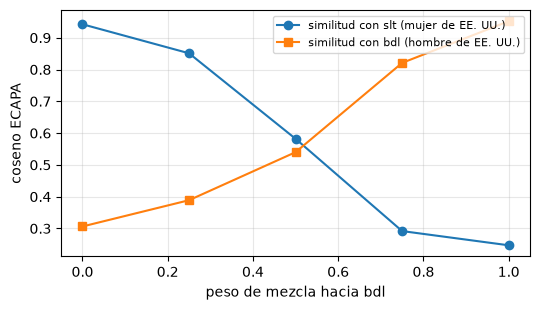

la mezcla tardó 10 s


In [18]:
t0 = time.time(); lams = [0, 0.25, 0.5, 0.75, 1.0]; ms, mb = [], []
for lam in lams:
    vec = F.normalize((1 - lam) * VOICE["slt"] + lam * VOICE["bdl"], dim=-1)
    e = emb(ecapa, speak(SENT[1], vec, seed=1))
    ms.append(float(e @ cent["slt"])); mb.append(float(e @ cent["bdl"]))
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.plot(lams, ms, "o-", label="similitud con slt (mujer de EE. UU.)"); ax.plot(lams, mb, "s-", label="similitud con bdl (hombre de EE. UU.)")
ax.set_xlabel("peso de mezcla hacia bdl"); ax.set_ylabel("coseno ECAPA"); ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("la mezcla tardó %.0f s" % (time.time() - t0))

**Lectura.** El espacio de embeddings es continuo y la mezcla se comporta con suavidad: la similitud con *slt* cae de 0,94 a 0,85, 0,58, 0,29 y 0,25 al mover el peso hacia *bdl*, mientras que la similitud con *bdl* sube de 0,31 a 0,39, 0,54, 0,82 y 0,95. Con un peso de 0,5 la voz está casi igual de lejos de ambas (0,58 y 0,54): es una voz que no pertenece a ninguna, que es la manera con fundamento de dar a un producto su propia voz sin imitar a nadie. La transición no es lineal: a un cuarto del camino la voz sigue sonando a *slt* para el juez, y la mayor parte del cambio ocurre entre 0,5 y 0,75.

### 6.4 Clonación de disparo cero con modelos de lenguaje de códec (explicada, no ejecutada)

Un x-vector es un *resumen* de una voz, unos cientos de números, y un TTS condicionado por él puede reproducir el timbre general pero poco del estilo, el acento o las condiciones de grabación del hablante: nuestro clon de arriba muestra el límite. Los sistemas de **disparo cero** (zero-shot) van más allá condicionando con el **propio audio**. **VALL-E** (Wang et al., 2023, [arXiv 2301.02111](https://arxiv.org/abs/2301.02111)) comprime primero el habla en **tokens de códec** discretos con un códec de audio neuronal (el codificador, el cuantizador y el decodificador de una red neuronal de compresión, ver el [módulo 06 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/06-generacion-de-audio-y-video/)). Después trata el TTS como **modelado del lenguaje**: un transformer grande se entrena con 60 000 horas de habla para continuar una secuencia de tokens, con la secuencia de fonemas del texto objetivo y un **fragmento de 3 segundos** de los tokens de códec del hablante objetivo como prefijo. La continuación es habla que dice el texto nuevo *con la voz del fragmento* y, como el fragmento lo lleva todo, también con su entorno de grabación y a menudo su emoción, sin entrenamiento por hablante: "disparo cero". Es la misma receta que los grandes modelos de lenguaje del [módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/), aplicada a tokens de audio.

No ejecutamos ninguno aquí: el original no se ha publicado, las reimplementaciones abiertas son grandes (y varias tienen licencias de pesos no comerciales, así que hay que comprobarlo antes de usarlas) y, siendo honestos, lo que demuestra es justo de lo que trata la sección 7. Tres segundos del habla de cualquier persona, de un buzón de voz, un vídeo o un pódcast, bastan para que la calidad engañe a los oyentes en las propias pruebas de los artículos, y por eso el consentimiento es la cuestión central y no una nota al pie.

## 7. Ética, consentimiento, fraude, detección, marcas de agua y ley

Todo lo de las secciones 4 a 6 es una tecnología de doble uso. Los usos buenos son reales: leer en voz alta para personas con discapacidad visual, devolver la voz a quien la perdió por una enfermedad (se puede "guardar" la voz de antemano), doblaje y accesibilidad, aprendizaje de idiomas. Los usos dañinos también son reales:

* **Fraude.** Una voz clonada derrota la comprobación de identidad más antigua que existe: "sonaba como mi hija". Las agencias de protección del consumidor han avisado de la **estafa de la emergencia familiar**, en la que quien llama con una voz clonada pide dinero urgente a un familiar ([reportaje de NPR sobre el aviso de la FTC, 2023](https://www.npr.org/2023/03/22/1165448073/that-panicky-call-from-a-relative-it-could-be-a-thief-using-a-voice-clone-ftc-warns)), y de la "autenticación por voz" de bancos y empresas, que un buen clon puede atacar. En 2024, unas llamadas automáticas que imitaban la voz de un líder político para pedir a la gente que no votara llevaron a la Comisión Federal de Comunicaciones de EE. UU. a dictaminar que las voces generadas por IA son voces "artificiales" según la ley telefónica de protección del consumidor ([dictamen declaratorio FCC 24-17](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf)).
* **Imitación sin consentimiento y acoso**, incluido el uso de la voz de un actor, un cantante o una persona privada sin permiso; **desinformación**, porque una grabación solía ser una prueba y ya no lo es por sí sola.
* **Privacidad.** Una voz es un dato **biométrico**: según el Reglamento General de Protección de Datos europeo, la voz tratada para identificar a una persona es una categoría especial con condiciones estrictas, y las grabaciones de conjuntos de datos públicos a menudo se publicaron sin que la gente imaginara este uso.

**Nuestras reglas en este cuaderno, y una pauta razonable para ti.** (1) Clona solo voces cuyo titular haya dado un consentimiento explícito e informado para ese uso concreto; una licencia sobre un conjunto de datos (como CC BY) permite reutilizar la *grabación*, no necesariamente imitar a la *persona*. (2) Prefiere voces sintéticas o diseñadas: cada voz aquí es una voz de corpus publicada para investigar el TTS o una mezcla de ellas. (3) Avisa de que el audio es sintético. (4) No uses una voz como contraseña, y acordad en la familia o la empresa una **comprobación por otro canal** (devolver la llamada a un número conocido, una palabra clave) ante cualquier petición urgente de dinero o secretos.

### 7.1 Detección: un juguete que funciona, y por qué no te salvará

Un **detector** es un clasificador de "grabación real o generada". Construimos el más simple: la media y la desviación típica de las 40 bandas log-mel durante los primeros 2,5 s de un clip (80 números), y luego una regresión logística. Clase real: clips de LibriSpeech (un solo lector, una limitación real). Clase sintética: nuestros clips de SpeechT5. Dividimos **por voz** en la clase sintética (ninguna voz de SpeechT5 aparece a la vez en entrenamiento y prueba; el único lector real se divide por clip), y probamos después cuatro cosas que el detector nunca vio: clips reales reservados, clips de SpeechT5 reservados, **los mismos clips reales comprimidos a 8 kHz y devueltos** (una transformación cotidiana: una llamada telefónica) y clips de un **generador distinto**, el modelo MMS-TTS en inglés (arquitectura VITS, un diseño distinto de SpeechT5 + HiFi-GAN).

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
N25 = 40000
def det_feat(a):
    a = np.asarray(a[:N25], dtype=np.float32); a = np.pad(a, (0, N25 - len(a)))
    m = logmel(a, 16000, 512, 160, 40).numpy(); return np.concatenate([m.mean(0), m.std(0)])

real = [("reader", c["audio"]) for c in ls_all if c["dur"] >= 2.5]
syn = [(k[0], a) for k, a in SPEECH.items() if len(a) >= 24000]
Xr = np.array([det_feat(a) for _, a in real]); Xs = np.array([det_feat(a) for _, a in syn])
fold_r = np.arange(len(real)) % 5; VOICES_ = sorted({g for g, _ in syn}); fold_s = np.array([VOICES_.index(g) % 5 for g, _ in syn])
X = np.vstack([Xr, Xs]); y = np.r_[np.zeros(len(Xr)), np.ones(len(Xs))]; fold = np.r_[fold_r, fold_s]
print("clips reales: %d (1 lector) | clips sintéticos de SpeechT5: %d (%d voces)" % (len(Xr), len(Xs), len(VOICES_)))

t0 = time.time()
eng = [mms(sx, "eng", seed=i) for i, sx in enumerate(SENT[:4])]; Xv = np.array([det_feat(a) for a in eng])        # un generador distinto (VITS)
phone = [resample_poly(resample_poly(a, 1, 2), 2, 1).astype(np.float32) for _, a in real]; Xp = np.array([det_feat(a) for a in phone])   # habla real con banda limitada
accs, fl = [], []
for f_ in range(5):
    tr, te = np.where(fold != f_)[0], np.where(fold == f_)[0]
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)).fit(X[tr], y[tr])
    te_r, te_s = te[y[te] == 0], te[y[te] == 1]
    accs.append(clf.score(X[te], y[te]))
    fl.append([clf.predict(X[te_r]).mean(), clf.predict(X[te_s]).mean(), clf.predict(Xp[te_r]).mean(), clf.predict(Xv).mean()])
fl = np.array(fl)
res = pd.Series({"exactitud con datos reservados (5 particiones, voces reservadas)": np.mean(accs),
                 "clips reales marcados como sintéticos": fl[:, 0].mean(),
                 "clips de SpeechT5 marcados (debería ser 1)": fl[:, 1].mean(),
                 "clips reales por un canal tipo teléfono de 8 kHz marcados": fl[:, 2].mean(),
                 "clips de MMS-TTS (VITS) marcados (generador no visto, debería ser 1)": fl[:, 3].mean()})
print(res.round(2).to_string()); print("el experimento del detector tardó %.0f s" % (time.time() - t0))

clips reales: 65 (1 lector) | clips sintéticos de SpeechT5: 24 (5 voces)


exactitud con datos reservados (5 particiones, voces reservadas)        0.93
clips reales marcados como sintéticos                                   0.00
clips de SpeechT5 marcados (debería ser 1)                              0.75
clips reales por un canal tipo teléfono de 8 kHz marcados               1.00
clips de MMS-TTS (VITS) marcados (generador no visto, debería ser 1)    1.00
el experimento del detector tardó 3 s


**Lectura.** La exactitud con datos reservados es del 93 %: los clips reales nunca se marcan (0 %) y el 75 % de los clips de SpeechT5 de voces no vistas sí. Los otros dos números son la lección. El generador no visto (MMS-TTS, VITS) se marca el 100 % de las veces, lo que parece una generalización excelente, pero los clips **reales** pasados por un canal de 8 kHz tipo teléfono también se marcan el 100 % de las veces: el detector ha aprendido "esto no se parece a la grabación de banda completa del único lector" en lugar de "esto fue generado". Cualquier cambio de micrófono, códec, volumen o idioma lo volteará, y nuestra clase real tiene un único lector, una prueba mucho más pobre que la que afronta un detector real. Los detectores de habla generada se entrenan con muchos generadores y condiciones de grabación, y aun así pierden exactitud con un generador que aparece después del entrenamiento, por lo que son una señal entre varias y nunca una prueba.

### 7.2 Marcas de agua: marcar el audio generado en el origen

La estrategia opuesta es que el **generador** deje una marca oculta que un detector busca con una clave secreta. La **marca de agua de espectro ensanchado** clásica suma al audio $a$ una secuencia de ruido pseudoaleatorio muy tenue $w$ determinada por una clave secreta $k$: $a' = a + \alpha\, w_k$. Para comprobar un clip, se correlaciona con la secuencia de la clave: el estadístico $z = a'\!\cdot w_k / \lVert a' \rVert$ es aproximadamente un número normal estándar si la marca no está (de modo que $z > 4$ tiene una probabilidad de unos 1 entre 30 000 de aparecer por azar) y crece como $\alpha\sqrt{N}$ (con $N$ el número de muestras) si está. Incrustamos con una relación señal-marca de 30 dB en 8 clips de SpeechT5 y luego atacamos el audio marcado de formas que le ocurren al audio en la vida real. Las marcas de agua aprendidas como AudioSeal (San Roman et al., 2024, [arXiv 2401.17264](https://arxiv.org/abs/2401.17264)) se entrenan contra esos ataques y pueden localizar las partes marcadas dentro de audios más largos; este juguete solo muestra el principio y los primeros obstáculos.

In [20]:
def wm_seq(n, key): return np.random.default_rng(key).standard_normal(n).astype(np.float32)
def wm_embed(a, key, snr_db=30):
    return a + wm_seq(len(a), key) * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10))
def wm_z(a, key): return float(a @ wm_seq(len(a), key) / np.linalg.norm(a))
def fit_len(a, n): return np.pad(a, (0, max(0, n - len(a))))[:n]

clips_wm = [say("slt", i)[:40000] for i in range(8)]; KEY = 1234
marked = [wm_embed(a, KEY) for a in clips_wm]
attacks = {"sin marca (control)": lambda a, o: o,
           "marcado, sin tocar": lambda a, o: a,
           "marcado, comprobado con clave equivocada": lambda a, o: a,
           "volumen x0,3": lambda a, o: 0.3 * a,
           "añadir ruido, SNR de 20 dB": lambda a, o: add_white(a, 20, 1),
           "canal de 8 kHz (paso bajo + remuestreo)": lambda a, o: fit_len(resample_poly(resample_poly(a, 1, 2), 2, 1), len(a)).astype(np.float32),
           "inicio recortado en 1 muestra": lambda a, o: fit_len(a[1:], len(a)),
           "cambio de velocidad del 3 %": lambda a, o: fit_len(resample_poly(a, 100, 103), len(a)).astype(np.float32)}
rows = []
for name, fn in attacks.items():
    zs = [wm_z(fn(m, o), 999 if "wrong" in name else KEY) for m, o in zip(marked, clips_wm)]
    rows.append(dict(condition=name, mean_z=round(float(np.mean(zs)), 1), detected=int(np.sum(np.array(zs) > 4)), out_of=8))
display(pd.DataFrame(rows))

,condition,mean_z,detected,out_of
0,sin marca (control),-0.4,0,8
1,"marcado, sin tocar",5.9,8,8
2,"marcado, comprobado con clave equivocada",5.9,8,8
3,"volumen x0,3",5.9,8,8
4,"añadir ruido, SNR de 20 dB",5.9,8,8
5,canal de 8 kHz (paso bajo + remuestreo),2.7,0,8
6,inicio recortado en 1 muestra,-0.3,0,8
7,cambio de velocidad del 3 %,-0.3,0,8


**Lectura.** Sin la marca, el estadístico es casi cero (media $-0{,}4$, 0 de 8 clips detectados con $z > 4$); con ella, $z \approx 5{,}9$ y se detectan 8 de 8; con la clave equivocada es 0,6 (0 de 8), de modo que solo quien tiene la clave puede leer la marca. Sobrevive a un cambio de volumen (el estadístico es invariante a la escala) y a ruido aditivo con 20 dB de relación señal-ruido, 10 dB más fuerte que la propia marca, porque el ruido no está correlacionado con la clave. **No** sobrevive a pasar por un canal de 8 kHz (media $z = 2{,}7$, 0 de 8), que elimina la mitad de la energía de la marca, ni a un desplazamiento de una muestra ni a un cambio de velocidad del 3 % (media $z = -0{,}3$): la secuencia clave deja de alinearse con el audio, y un detector ingenuo tendría que buscar entre todos los desplazamientos y velocidades. Una marca de ruido blanco de 30 dB además se oye ligeramente como siseo. Estos son los problemas que las marcas de agua aprendidas se entrenan para resolver, y aun así un atacante decidido puede eliminarlas (por ejemplo resintetizando el habla), de modo que una marca de agua ayuda a los proveedores honestos y a la rendición de cuentas pero no detiene a uno malintencionado.

### 7.3 El marco legal

La ley avanza deprisa y cambia según el país; esto es un mapa, no asesoramiento jurídico.

* **Unión Europea.** La Ley de Inteligencia Artificial ([Reglamento (UE) 2024/1689](https://eur-lex.europa.eu/eli/reg/2024/1689/oj)), [artículo 50](https://artificialintelligenceact.eu/article/50/), obliga a los proveedores de sistemas que generan audio sintético a marcar sus salidas de forma legible por máquina y a quienes despliegan ultrafalsificaciones (deepfakes) a avisar de que el contenido está generado o manipulado artificialmente. El Reglamento General de Protección de Datos se aplica a la voz como dato personal (y, cuando se usa para identificar, biométrico).
* **Estados Unidos.** El [dictamen de la FCC](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf) citado arriba somete las llamadas automáticas con voz de IA a la ley telefónica de protección del consumidor, que en general exige el consentimiento previo del destinatario. Varios estados han añadido derechos sobre la propia voz y la imagen.
* **En todas partes.** El fraude, la suplantación y el acoso ya son delitos sea cual sea la herramienta, y existen derechos sobre la voz y la imagen de una persona en muchos ordenamientos; las condiciones de las plataformas de los proveedores de modelos añaden más límites (varios modelos TTS abiertos se distribuyen con una licencia no comercial o de "no suplantación").

Como profesional: obtén consentimiento por escrito para cualquier voz clonada, conserva un registro, etiqueta el audio generado, marca con agua lo que generes cuando puedas, trata los detectores como una señal débil más y diseña los sistemas de modo que **una voz por sí sola nunca autorice nada**.

## 8. Ideas clave, ejercicios, referencias

### Ideas clave

1. **Los modelos de voz trabajan con rasgos log-mel**: una forma de onda se corta en ventanas de 25 ms, se convierte en energías en una escala mel y se pasa a logaritmo; el ASR convierte esa imagen en texto, el TTS convierte texto en ella y un vocoder la devuelve a audio.
2. **CTC** elimina la necesidad de etiquetas por fotograma sumando sobre todas las alineaciones con un símbolo en blanco; se entrena con un programa dinámico, produce posteriores picudos y no tiene conocimiento del idioma, así que decodificar con un léxico o un modelo de lenguaje ayuda. Un reconocedor desde cero es preciso con voces que ha oído y se degrada con un locutor desconocido (sección 2).
3. **Los reconocedores preentrenados son la herramienta adecuada para el trabajo real.** Whisper, entrenado con un corpus web enorme y variado, es mucho más robusto que cualquier cosa que podamos entrenar en un portátil, pero robusto no es infalible: el ruido eleva la WER, los acentos importan y con entradas sin habla puede **alucinar** texto fluido. Añade una puerta de actividad de voz y comprueba las señales de "no hay habla" del modelo (sección 3).
4. **TTS = front-end de texto + modelo acústico + vocoder**, y su calidad puede sondearse sin escuchar con la WER de ida y vuelta, con la salvedad de que el juez puede reparar errores y no dice nada de la naturalidad (sección 4).
5. **Las cascadas son modulares pero acumulan errores**; la calidad de la traducción de voz está limitada por su etapa más débil, y el cuello de botella del texto pierde la voz y la prosodia del hablante (sección 5).
6. **Una voz es un punto en un espacio de embeddings.** Condicionar un TTS con un embedding da una imitación aproximada a partir de una referencia corta; los modelos de lenguaje de códec de disparo cero lo hacen mucho mejor con tres segundos de audio, y por eso el **consentimiento, el aviso, las marcas de agua y la verificación por otro canal** son requisitos de ingeniería (secciones 6 y 7).
7. **Los detectores entrenados con un generador no deben usarse con otro**, y una marca de agua simple sobrevive al ruido y al filtrado pero no a la desincronización; la defensa necesita varias capas, no un solo modelo.

### Ejercicios

1. En la sección 2, cambia el ancho del haz de 8 a 1, 2, 4 y 16 y dibuja la WER con el locutor no visto. ¿Cuándo deja de ayudar ampliarlo? Después cambia la bonificación $\beta$ del léxico y encuentra el valor que minimiza la WER.
2. Entrena el modelo CTC retirando el *grupo de acento* del locutor no visto (el otro locutor con acento alemán, *yweweler*) en lugar de retirar a *lucas*. ¿Cambia el error con el locutor reservado y qué dice eso sobre la cobertura de los datos?
3. Sustituye las dos convoluciones con paso por una sola (submuestreo por 2). Comprueba que CTC sigue entrenándose y compara tiempo y WER. ¿Cuál es la transcripción más larga por segundo de audio que CTC puede representar con submuestreo por 4 y salto de 10 ms?
4. Repite el experimento de ruido de la sección 3.2 con otro ruido: un tono de 1 kHz o ruido filtrado paso bajo. ¿Cambia el orden de los tres reconocedores?
5. Ejecuta Whisper con `language=None` sobre los clips ruidosos y cuenta con qué frecuencia es erróneo el idioma detectado a 0 dB. Añade una regla basada en la confianza de la identificación de idioma para rechazar esos casos.
6. En la sección 6.2, registra el clon a partir de la *segunda* frase y de un clip con 2 s de silencio añadidos. ¿Cuán sensible es la voz clonada a la referencia?
7. Amplía el detector de la sección 7.1 con algunos rasgos adicionales (planitud espectral, variabilidad del tono) y mide si generaliza a los clips VITS. ¿Por qué "funciona con mi conjunto de prueba" no es la pregunta que importa?
8. Debate: un banco ofrece autenticación por voz a sus clientes. Escribe el modelo de amenazas y enumera tres controles (técnico, de procedimiento y legal) que añadirías.

### Referencias

* Graves, A., Fernández, S., Gomez, F. y Schmidhuber, J. (2006). Connectionist temporal classification: labelling unsegmented sequence data with recurrent neural networks. ICML. [artículo](https://www.cs.toronto.edu/~graves/icml_2006.pdf), [doi:10.1145/1143844.1143891](https://doi.org/10.1145/1143844.1143891).
* Hannun, A. (2017). Sequence modeling with CTC. Distill. [distill.pub/2017/ctc](https://distill.pub/2017/ctc/). Hannun, A. Y., Maas, A. L., Jurafsky, D. y Ng, A. Y. (2014). First-pass large vocabulary continuous speech recognition using bi-directional recurrent DNNs. [arXiv 1408.2873](https://arxiv.org/abs/1408.2873).
* Radford, A., Kim, J. W., Xu, T., Brockman, G., McLeavey, C. y Sutskever, I. (2022). Robust speech recognition via large-scale weak supervision (Whisper). [arXiv 2212.04356](https://arxiv.org/abs/2212.04356).
* Baevski, A., Zhou, H., Mohamed, A. y Auli, M. (2020). wav2vec 2.0: a framework for self-supervised learning of speech representations. [arXiv 2006.11477](https://arxiv.org/abs/2006.11477).
* Ao, J. et al. (2021). SpeechT5: unified-modal encoder-decoder pre-training for spoken language processing. [arXiv 2110.07205](https://arxiv.org/abs/2110.07205).
* Kong, J., Kim, J. y Bae, J. (2020). HiFi-GAN: generative adversarial networks for efficient and high fidelity speech synthesis. [arXiv 2010.05646](https://arxiv.org/abs/2010.05646).
* Desplanques, B., Thienpondt, J. y Demuynck, K. (2020). ECAPA-TDNN: emphasized channel attention, propagation and aggregation in TDNN based speaker verification. [arXiv 2005.07143](https://arxiv.org/abs/2005.07143).
* Snyder, D., Garcia-Romero, D., Sell, G., Povey, D. y Khudanpur, S. (2018). X-vectors: robust DNN embeddings for speaker recognition. ICASSP. [doi:10.1109/ICASSP.2018.8461375](https://doi.org/10.1109/ICASSP.2018.8461375).
* Wang, C. et al. (2023). Neural codec language models are zero-shot text to speech synthesizers (VALL-E). [arXiv 2301.02111](https://arxiv.org/abs/2301.02111).
* Tiedemann, J. y Thottingal, S. (2020). OPUS-MT, building open translation services for the world. EAMT. [ACL Anthology](https://aclanthology.org/2020.eamt-1.61/).
* Pratap, V. et al. (2023). Scaling speech technology to 1,000+ languages (MMS). [arXiv 2305.13516](https://arxiv.org/abs/2305.13516).
* Ravanelli, M. et al. (2021). SpeechBrain: a general-purpose speech toolkit. [arXiv 2106.04624](https://arxiv.org/abs/2106.04624).
* San Roman, R., Fernandez, P., Defossez, A. et al. (2024). Proactive detection of voice cloning with localized watermarking (AudioSeal). [arXiv 2401.17264](https://arxiv.org/abs/2401.17264).
* Jackson, Z., Souza, C., Flaks, J., Pan, Y., Nicolas, H. y Thite, A. (2018). Free Spoken Digit Dataset. [doi:10.5281/zenodo.1342401](https://doi.org/10.5281/zenodo.1342401), [GitHub](https://github.com/Jakobovski/free-spoken-digit-dataset).
* Panayotov, V., Chen, G., Povey, D. y Khudanpur, S. (2015). LibriSpeech: an ASR corpus based on public domain audio books. ICASSP. [doi:10.1109/ICASSP.2015.7178964](https://doi.org/10.1109/ICASSP.2015.7178964).
* Kominek, J. y Black, A. W. (2004). The CMU Arctic speech databases. ISCA Speech Synthesis Workshop. [artículo](https://www.isca-archive.org/ssw_2004/kominek04b_ssw.pdf).
* Reglamento (UE) 2024/1689 (Ley de Inteligencia Artificial). [EUR-Lex](https://eur-lex.europa.eu/eli/reg/2024/1689/oj), [artículo 50](https://artificialintelligenceact.eu/article/50/). FCC (2024). Dictamen declaratorio FCC 24-17 sobre voces generadas por IA en llamadas automáticas. [PDF](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf).